# ECCO Procurement: Chronological PostgreSQL Investigation

This notebook is a professional, evidence-based investigation of the ECCO-style procurement database. It starts with the business question, discovers the live PostgreSQL structure, studies each table independently, follows the business relationships, validates cross-table behavior, and only then assesses readiness for future commodity-price analysis.

**Data safety:** PostgreSQL is the only source of business data used in this notebook. The notebook reads the existing `.env` connection settings, never displays credentials, never loads source CSV files for analysis, never creates a database, and never modifies the existing database.

# STAGE 01 — Understand the business before investigating the database

ECCO-style footwear production depends on materials such as leather, textiles, rubber, chemicals, and other inputs. Vendors supply those materials to production plants under sourcing arrangements with prices, currencies, lead times, quantities, and approval periods.

Procurement cost can change because:

- international commodity markets move;
- vendors quote in different currencies;
- exchange rates change the EUR cost;
- supplier contracts start, expire, or change;
- goods receipts may arrive after the order month;
- plants and vendors use different measurement units; and
- supplier delivery and quality performance can affect operational decisions.

### Primary analytical objective

Understand whether historical raw-material procurement prices can later be compared with related commodity-market movements and supplier-related factors.

Before correlation analysis is attempted, the investigation must establish the procurement grain, valid supplier/material/plant relationships, comparable units, reliable FX normalization, commodity exposure mappings, time coverage, and the difference between zero activity and a missing observation.

**Research Question:** What information does ECCO need to understand from its procurement database?

**Expected Outcome:** Establish the business context and a defensible investigation path before making analytical claims.

In [3]:
# 1. Imports, PostgreSQL connection, and investigation-log helpers
import os
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from IPython.display import Markdown, display
from sqlalchemy import URL, create_engine, text
from sqlalchemy.exc import SQLAlchemyError

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / ".env").exists() and (candidate / "requirements.txt").exists():
            return candidate
    raise FileNotFoundError("Could not locate project root containing .env and requirements.txt.")

PROJECT_ROOT = find_project_root()
load_dotenv(PROJECT_ROOT / ".env")
required = ["PGDATABASE", "PGUSER", "PGPASSWORD"]
missing = [name for name in required if not os.getenv(name)]
if missing:
    raise ValueError(f"Missing environment variables: {', '.join(missing)}")

DB_HOST = os.getenv("PGHOST", "localhost")
DB_PORT = int(os.getenv("PGPORT", "5432"))
DB_NAME = os.environ["PGDATABASE"]
DB_USER = os.environ["PGUSER"]
database_url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_USER,
    password=os.environ["PGPASSWORD"],
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)
engine = create_engine(database_url, pool_pre_ping=True)
with engine.connect() as connection:
    db_name, db_user, server_version = connection.execute(
        text("SELECT current_database(), current_user, version()")
    ).one()

def sql_df(query, params=None):
    with engine.connect() as connection:
        return pd.read_sql_query(text(query), connection, params=params)

def quote_identifier(identifier):
    return '"' + str(identifier).replace('"', '""') + '"'

def qualified_table(table_name, schema_name="public"):
    return f"{quote_identifier(schema_name)}.{quote_identifier(table_name)}"

investigation_log = []

def add_log(
    investigation_id, stage, source, field_or_relationship, question,
    observation, validation, evidence, finding, severity, action,
    mentor_clarification, status,
):
    investigation_log.append({
        "investigation_id": investigation_id,
        "stage": stage,
        "source": source,
        "field_or_relationship": field_or_relationship,
        "business_question": question,
        "observation": observation,
        "validation_performed": validation,
        "evidence": evidence,
        "finding": finding,
        "severity": severity,
        "recommended_action": action,
        "mentor_clarification": mentor_clarification,
        "status": status,
    })

TABLE_PURPOSES = {
    "dim_material": ("materials and SKUs used in production", "one material/SKU master row"),
    "dim_vendor": ("supplier identity and commercial classification", "one vendor master row"),
    "dim_plant": ("production locations receiving materials", "one plant master row"),
    "dim_purchasing_org": ("procurement responsibility", "one purchasing organization row"),
    "dim_commodity": ("market benchmarks associated with material exposure", "one commodity-index row"),
    "bridge_vendor_material": ("approved vendor-material-plant sourcing arrangements", "one approved sourcing relationship"),
    "bridge_material_commodity": ("material exposure weights and time lags", "one material-commodity mapping"),
    "fact_procurement_monthly": ("monthly orders, receipts, spend, and recorded prices", "vendor-material-plant-month aggregate"),
    "fact_commodity_monthly": ("monthly commodity benchmark history", "commodity-month observation"),
    "fact_fx_monthly": ("monthly EUR exchange-rate normalization", "month-currency rate"),
    "fact_vendor_performance_quarterly": ("quarterly supplier delivery and quality context", "vendor-plant-quarter observation"),
}

print(f"Connected to PostgreSQL database: {db_name}")
print(f"PostgreSQL user: {db_user}")
print(f"Server: {server_version.split(',')[0]}")
print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__}")

Connected to PostgreSQL database: ecco_procurement
PostgreSQL user: postgres
Server: PostgreSQL 18.4 on x86_64-windows
Python: 3.14.4 | Pandas: 3.1.0


# EDA DATA REPORT 

## STAGE 02 — Discover the PostgreSQL database before inspecting individual tables

**Why am I investigating this?** I need to understand the database boundary and its implemented structure before deciding which tables or columns could answer the business question.

**What information did I examine?** Schemas, tables, row counts, columns, PostgreSQL data types, nullability, constraints, indexes, and the repository ER diagram as design documentation.

**What questions emerged?** Do the implemented foreign keys match the intended business relationships? Which tables are dimensions, bridges, facts, or supporting references? Are important relationships represented only by conventions rather than database constraints?

In [4]:
# 2. Database inventory: schemas, objects, and exact PostgreSQL row counts
schemas = sql_df('''
    SELECT schema_name
    FROM information_schema.schemata
    WHERE schema_name NOT IN ('pg_catalog', 'information_schema')
    ORDER BY schema_name
''')
objects = sql_df('''
    SELECT table_schema, table_name, table_type
    FROM information_schema.tables
    WHERE table_schema NOT IN ('pg_catalog', 'information_schema')
    ORDER BY table_schema, table_name
''')
objects["row_count"] = [
    int(sql_df(f"SELECT COUNT(*) AS n FROM {qualified_table(row.table_name, row.table_schema)}").iloc[0, 0])
    if row.table_type == "BASE TABLE" else pd.NA
    for row in objects.itertuples()
]
objects["category"] = objects["table_name"].map({
    "dim_material": "dimension", "dim_vendor": "dimension",
    "dim_plant": "dimension", "dim_purchasing_org": "dimension",
    "dim_commodity": "dimension", "bridge_vendor_material": "bridge",
    "bridge_material_commodity": "bridge", "fact_procurement_monthly": "fact",
    "fact_commodity_monthly": "fact", "fact_fx_monthly": "fact",
    "fact_vendor_performance_quarterly": "fact",
    "data_quality_issue_register": "reference",
}).fillna("other")
display(Markdown("### What I observed"))
display(Markdown(f"PostgreSQL exposes **{len(schemas):,} non-system schemas** and **{len(objects):,} user tables/views**."))
display(schemas)
display(objects)
display(Markdown("**What I understood:** the database separates master data, sourcing relationships, monthly facts, quarterly facts, and a documented issue register. I can now investigate each business subject in a controlled order."))

### What I observed

PostgreSQL exposes **18 non-system schemas** and **27 user tables/views**.

,schema_name
0,audit
1,pg_temp_11
2,pg_temp_12
3,pg_temp_14
4,pg_temp_39
5,pg_temp_45
6,pg_temp_48
7,pg_temp_51
8,pg_toast
9,pg_toast_temp_11


,table_schema,table_name,table_type,row_count,category
0,audit,performance_duplicate_review,BASE TABLE,102627,other
1,audit,price_reconciliation_review,BASE TABLE,698552,other
2,audit,procurement_duplicate_review,BASE TABLE,785,other
3,audit,procurement_exceptions,BASE TABLE,545391,other
4,audit,transformation_run,BASE TABLE,10,other
5,public,bridge_material_commodity,BASE TABLE,3600,bridge
6,public,bridge_vendor_material,BASE TABLE,2910,bridge
7,public,data_quality_issue_register,BASE TABLE,2054,reference
8,public,dim_commodity,BASE TABLE,13,dimension
9,public,dim_material,BASE TABLE,1200,dimension


**What I understood:** the database separates master data, sourcing relationships, monthly facts, quarterly facts, and a documented issue register. I can now investigate each business subject in a controlled order.

In [5]:
# 3. Implemented schema metadata: columns, constraints, indexes, and ER documentation
columns = sql_df('''
    SELECT table_schema, table_name, ordinal_position, column_name,
           data_type, is_nullable, character_maximum_length
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
''')
constraints = sql_df('''
    SELECT tc.table_name, tc.constraint_name, tc.constraint_type,
           kcu.column_name, ccu.table_name AS referenced_table,
           ccu.column_name AS referenced_column
    FROM information_schema.table_constraints tc
    LEFT JOIN information_schema.key_column_usage kcu
      ON tc.constraint_schema = kcu.constraint_schema
     AND tc.constraint_name = kcu.constraint_name
     AND tc.table_name = kcu.table_name
    LEFT JOIN information_schema.constraint_column_usage ccu
      ON tc.constraint_schema = ccu.constraint_schema
     AND tc.constraint_name = ccu.constraint_name
    WHERE tc.table_schema = 'public'
    ORDER BY tc.table_name, tc.constraint_name, kcu.ordinal_position
''')
indexes = sql_df('''
    SELECT schemaname, tablename, indexname, indexdef
    FROM pg_indexes
    WHERE schemaname = 'public'
    ORDER BY tablename, indexname
''')
er_path = PROJECT_ROOT / "data" / "er_diagram.mmd"
er_documentation = er_path.read_text(encoding="utf-8") if er_path.exists() else "ER diagram file not found."
print(f"Column definitions discovered: {len(columns):,}")
print(f"Constraint metadata rows: {len(constraints):,}")
print(f"Indexes discovered: {len(indexes):,}")
display(columns.head(30))
display(constraints)
display(Markdown("### ER design documentation inspected"))
display(Markdown("The repository ER diagram is treated as design documentation; live PostgreSQL metadata remains the authority for implemented constraints."))
print(er_documentation[:1200])

Column definitions discovered: 99
Constraint metadata rows: 127
Indexes discovered: 16


,table_schema,table_name,ordinal_position,column_name,data_type,is_nullable,character_maximum_length
0,public,bridge_material_commodity,1,material_id,text,NO,None
1,public,bridge_material_commodity,2,commodity_id,text,NO,None
2,public,bridge_material_commodity,3,exposure_weight,numeric,NO,None
3,public,bridge_material_commodity,4,lag_months,integer,NO,None
4,public,bridge_material_commodity,5,mapping_confidence,text,NO,None
5,public,bridge_material_commodity,6,valid_from,date,NO,None
6,public,bridge_vendor_material,1,vendor_material_id,text,NO,None
7,public,bridge_vendor_material,2,material_id,text,NO,None
8,public,bridge_vendor_material,3,vendor_id,text,NO,None
9,public,bridge_vendor_material,4,plant_id,text,NO,None


,table_name,constraint_name,constraint_type,column_name,referenced_table,referenced_column
0,bridge_material_commodity,bridge_material_commodity_commodity_id_fkey,FOREIGN KEY,commodity_id,dim_commodity,commodity_id
1,bridge_material_commodity,bridge_material_commodity_commodity_id_not_null,CHECK,NaN,bridge_material_commodity,commodity_id
2,bridge_material_commodity,bridge_material_commodity_exposure_weight_not_null,CHECK,NaN,bridge_material_commodity,exposure_weight
3,bridge_material_commodity,bridge_material_commodity_lag_months_not_null,CHECK,NaN,bridge_material_commodity,lag_months
4,bridge_material_commodity,bridge_material_commodity_mapping_confidence_not_null,CHECK,NaN,bridge_material_commodity,mapping_confidence
...,...,...,...,...,...,...
122,fact_vendor_performance_quarterly,fact_vendor_performance_quarterly_price_variance_pct_not_null,CHECK,NaN,fact_vendor_performance_quarterly,price_variance_pct
123,fact_vendor_performance_quarterly,fact_vendor_performance_quarterly_quarter_end_not_null,CHECK,NaN,fact_vendor_performance_quarterly,quarter_end
124,fact_vendor_performance_quarterly,fact_vendor_performance_quarterly_quarter_start_not_null,CHECK,NaN,fact_vendor_performance_quarterly,quarter_start
125,fact_vendor_performance_quarterly,fact_vendor_performance_quarterly_vendor_id_fkey,FOREIGN KEY,vendor_id,dim_vendor,vendor_id


### ER design documentation inspected

The repository ER diagram is treated as design documentation; live PostgreSQL metadata remains the authority for implemented constraints.

erDiagram
    DIM_PURCHASING_ORG ||--o{ DIM_PLANT : manages
    DIM_PLANT ||--o{ BRIDGE_VENDOR_MATERIAL : supplies_to
    DIM_VENDOR ||--o{ BRIDGE_VENDOR_MATERIAL : offers
    DIM_MATERIAL ||--o{ BRIDGE_VENDOR_MATERIAL : sourced_as
    BRIDGE_VENDOR_MATERIAL ||--o{ FACT_PROCUREMENT_MONTHLY : records
    DIM_VENDOR ||--o{ FACT_VENDOR_PERFORMANCE_QUARTERLY : assessed
    DIM_PLANT ||--o{ FACT_VENDOR_PERFORMANCE_QUARTERLY : receives_at
    DIM_MATERIAL ||--o{ BRIDGE_MATERIAL_COMMODITY : exposed_to
    DIM_COMMODITY ||--o{ BRIDGE_MATERIAL_COMMODITY : influences
    DIM_COMMODITY ||--o{ FACT_COMMODITY_MONTHLY : indexed_by
    FACT_FX_MONTHLY }o--o{ FACT_PROCUREMENT_MONTHLY : converts_currency_month
    DIM_PURCHASING_ORG { string purch_org_id PK }
    DIM_PLANT { string plant_id PK string purch_org_id FK }
    DIM_VENDOR { string vendor_id PK }
    DIM_MATERIAL { string material_id PK string material_7 }
    BRIDGE_VENDOR_MATERIAL { string vendor_material_id PK string material_id FK string 

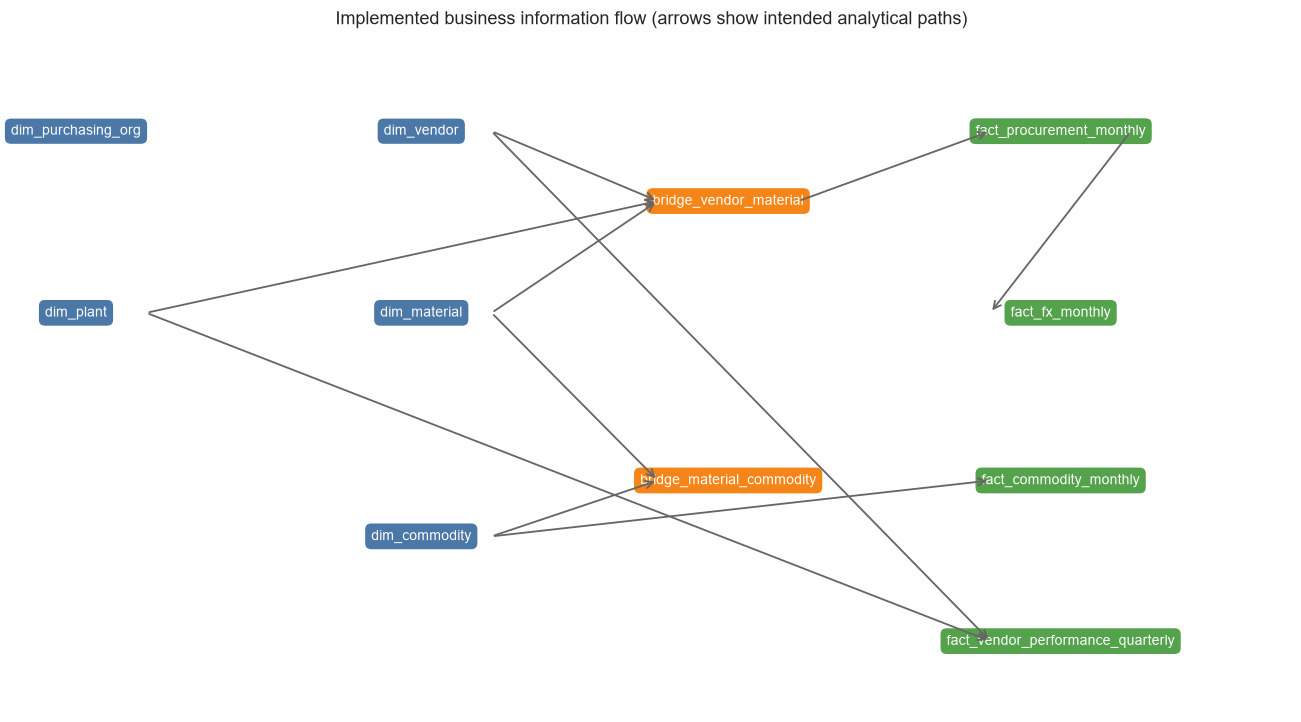

**What I observed:** procurement is not a standalone table. It depends on sourcing relationships, material and plant masters, FX rates, and supporting commodity and performance facts. **Next step:** study each table independently before using these joins.

In [6]:
# 4. High-level relationship map: dimensions, bridges, and facts
relationship_edges = [
    ("dim_purchasing_org", "dim_plant", "purch_org_id"),
    ("dim_plant", "bridge_vendor_material", "plant_id"),
    ("dim_vendor", "bridge_vendor_material", "vendor_id"),
    ("dim_material", "bridge_vendor_material", "material_id"),
    ("bridge_vendor_material", "fact_procurement_monthly", "vendor_material_id"),
    ("dim_material", "bridge_material_commodity", "material_id"),
    ("dim_commodity", "bridge_material_commodity", "commodity_id"),
    ("dim_commodity", "fact_commodity_monthly", "commodity_id"),
    ("fact_procurement_monthly", "fact_fx_monthly", "month + currency"),
    ("dim_vendor", "fact_vendor_performance_quarterly", "vendor_id"),
    ("dim_plant", "fact_vendor_performance_quarterly", "plant_id"),
]
fig, ax = plt.subplots(figsize=(15, 8))
positions = {
    "dim_purchasing_org": (0.05, 0.78), "dim_plant": (0.05, 0.52),
    "dim_vendor": (0.32, 0.78), "dim_material": (0.32, 0.52),
    "dim_commodity": (0.32, 0.20), "bridge_vendor_material": (0.56, 0.68),
    "bridge_material_commodity": (0.56, 0.28), "fact_procurement_monthly": (0.82, 0.78),
    "fact_commodity_monthly": (0.82, 0.28), "fact_fx_monthly": (0.82, 0.52),
    "fact_vendor_performance_quarterly": (0.82, 0.05),
}
colors = {"dimension": "#4c78a8", "bridge": "#f58518", "fact": "#54a24b"}
for table_name, (x, y) in positions.items():
    category = objects.loc[objects["table_name"].eq(table_name), "category"].iloc[0]
    ax.text(x, y, table_name, ha="center", va="center", fontsize=9, color="white",
            bbox={"boxstyle": "round,pad=0.5", "facecolor": colors.get(category, "#777777")})
for left, right, key in relationship_edges:
    x1, y1 = positions[left]
    x2, y2 = positions[right]
    ax.annotate("", xy=(x2 - 0.055, y2), xytext=(x1 + 0.055, y1),
                arrowprops={"arrowstyle": "->", "color": "#666666", "lw": 1.2})
ax.set_xlim(0, 1); ax.set_ylim(-0.05, 0.92); ax.axis("off")
ax.set_title("Implemented business information flow (arrows show intended analytical paths)")
plt.show()
display(Markdown("**What I observed:** procurement is not a standalone table. It depends on sourcing relationships, material and plant masters, FX rates, and supporting commodity and performance facts. **Next step:** study each table independently before using these joins."))

### Stage 02 conclusion

**What I observed:** The live database contains the expected dimension, bridge, fact, and reference layers.

**What I understood:** The central analytical path is `fact_procurement_monthly → bridge_vendor_material → dim_material/dim_vendor/dim_plant`, with separate paths to FX, commodity exposure/history, and quarterly vendor performance.

**Questions for further investigation:** Which tables are complete enough to support those paths? Which fields are descriptive copies rather than canonical keys? Where do database constraints differ from business expectations?

**Next step:** investigate the tables in business order, starting with what ECCO purchases.

## STAGE 03 — Research the individual tables in business order

I will not begin with a global issue checklist. For every table, I will:

1. explain its business purpose and expected grain;
2. inspect live PostgreSQL samples, counts, nulls, types, ranges, and categories;
3. describe patterns that appear in the data;
4. turn observations into investigation questions;
5. validate only the rules relevant to that table;
6. record evidence, business meaning, remediation, and mentor clarification in the investigation log; and
7. explain why the next table is needed.

In [7]:
# 5. Reusable table-research functions: every observation comes from PostgreSQL
def table_columns(table_name):
    return columns.loc[columns["table_name"].eq(table_name)].sort_values("ordinal_position")

def table_profile(table_name, purpose, grain, categorical_columns=(), numeric_columns=(), date_columns=()):
    table = qualified_table(table_name)
    table_meta = table_columns(table_name)
    row_count = int(sql_df(f"SELECT COUNT(*) AS n FROM {table}").iloc[0, 0])
    null_expr = ", ".join(
        f"COUNT(*) FILTER (WHERE {quote_identifier(column)} IS NULL) AS {quote_identifier(column + '_nulls')}"
        for column in table_meta["column_name"]
    )
    nulls = sql_df(f"SELECT {null_expr} FROM {table}").T.reset_index()
    nulls.columns = ["column_name", "null_count"]
    nulls["null_rate_pct"] = (100 * nulls["null_count"] / max(row_count, 1)).round(3)
    sample = sql_df(f"SELECT * FROM {table} LIMIT 5")
    display(Markdown(f"### {table_name}: {purpose}"))
    display(Markdown(f"**Expected grain:** {grain}  \n**Observed row count:** {row_count:,}  \n**Columns:** {len(table_meta):,}"))
    display(Markdown("**Sample records from PostgreSQL:**"))
    display(sample)
    display(Markdown("**Missing-value profile:**"))
    display(nulls.sort_values("null_count", ascending=False).head(15))
    for column in categorical_columns:
        if column in table_meta["column_name"].tolist():
            values = sql_df(f'''
                SELECT {quote_identifier(column)} AS value, COUNT(*) AS row_count
                FROM {table}
                GROUP BY {quote_identifier(column)}
                ORDER BY row_count DESC, value NULLS FIRST
                LIMIT 12
            ''')
            display(Markdown(f"**Most common `{column}` values:**"))
            display(values)
    for column in numeric_columns:
        if column in table_meta["column_name"].tolist():
            summary = sql_df(f'''
                SELECT MIN({quote_identifier(column)}) AS minimum,
                       percentile_cont(0.5) WITHIN GROUP (ORDER BY {quote_identifier(column)}) AS median,
                       MAX({quote_identifier(column)}) AS maximum
                FROM {table}
            ''')
            display(Markdown(f"**Range for `{column}`:**"))
            display(summary)
    for column in date_columns:
        if column in table_meta["column_name"].tolist():
            dates = sql_df(f'''
                SELECT MIN({quote_identifier(column)}) AS first_date,
                       MAX({quote_identifier(column)}) AS last_date
                FROM {table}
            ''')
            display(Markdown(f"**Date coverage for `{column}`:**"))
            display(dates)
    return row_count, nulls

def log_table_observation(
    investigation_id, table_name, field, question, observation, validation,
    evidence, finding, severity, action, clarification, status="Observed",
):
    add_log(
        investigation_id, "STAGE 03", table_name, field, question, observation,
        validation, evidence, finding, severity, action, clarification, status,
    )

### 3.1 Understand what ECCO purchases — `dim_material`

**Why am I investigating this?** Material and SKU definitions are the foundation for interpreting every procurement quantity, unit price, and commodity exposure.

**What information will I examine?** material identifiers, descriptions, material groups, product categories, base units, and active periods.

In [8]:
# Independent observation: dim_material
row_count, nulls = table_profile(
    "dim_material",
    TABLE_PURPOSES["dim_material"][0],
    TABLE_PURPOSES["dim_material"][1],
    categorical_columns=['material_group_name', 'product_category', 'base_uom'],
    numeric_columns=[],
    date_columns=['active_from', 'active_to'],
)
# display(Markdown(
#     "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
#     "and value patterns before any issue is declared. "
#     "**Questions from this observation:** Are the distributions plausible for the stated grain, "
#     "and do any fields need a business-rule explanation?"
# ))

### dim_material: materials and SKUs used in production

**Expected grain:** one material/SKU master row  
**Observed row count:** 1,200  
**Columns:** 9

**Sample records from PostgreSQL:**

,material_id,material_7,material_description,material_group_id,material_group_name,base_uom,product_category,active_from,active_to
0,C22000000001,C220000,Pure sock - Vitrus Mondial,050122,Lining,PAA,Casual,2020-01-01,2025-12-31
1,C22000000002,C220000,Leather upper - Performance 001,050110,Leather upper,SQM,Sport,2020-02-01,None
2,C22000000003,C220000,Outsole - Urban 001,050210,Outsole,PAA,Formal,2020-03-01,None
3,C22000000004,C220000,Midsole - Kids 001,050220,Midsole,PAA,Outdoor,2020-04-01,None
4,C22000000005,C220000,Insole - Outdoor 001,050230,Insole,PAA,Casual,2020-05-01,None


**Missing-value profile:**

,column_name,null_count,null_rate_pct
8,active_to_nulls,1136,94.667
0,material_id_nulls,0,0.000
1,material_7_nulls,0,0.000
3,material_group_id_nulls,0,0.000
2,material_description_nulls,0,0.000
4,material_group_name_nulls,0,0.000
5,base_uom_nulls,0,0.000
6,product_category_nulls,0,0.000
7,active_from_nulls,0,0.000


... (6 outputs left out)

**Date coverage for `active_from`:**

,first_date,last_date
0,2020-01-01,2020-08-01


**Date coverage for `active_to`:**

,first_date,last_date
0,2025-12-31,2025-12-31


 What I observed: The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. Questions from this observation: Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

In [9]:
# Material validation hypotheses formed from the observed master data
material_checks = sql_df('''
    SELECT
        COUNT(*) FILTER (WHERE material_id IS NULL OR material_id = '') AS missing_material_ids,
        COUNT(*) FILTER (WHERE material_description IS NULL OR BTRIM(material_description) = '') AS missing_descriptions,
        COUNT(*) FILTER (WHERE active_to IS NOT NULL AND active_to < active_from) AS invalid_active_periods,
        COUNT(*) - COUNT(DISTINCT material_id) AS duplicate_material_id_rows,
        COUNT(*) FILTER (WHERE base_uom NOT IN ('KG', 'M', 'SQM', 'PA', 'PCS')) AS unexpected_units
    FROM public.dim_material
''')
display(material_checks)
m = material_checks.iloc[0]
log_table_observation("MAT-01", "dim_material", "material_id", "Can every procurement row be tied to one material master record?",
    "The material master defines the vocabulary used by downstream facts.",
    "Checked null identifiers, duplicate identifiers, descriptions, units, and active date ordering.",
    f"{int(m['duplicate_material_id_rows']):,} duplicate identifier rows; {int(m['missing_descriptions']):,} missing descriptions.",
    "Material master key and descriptive completeness require monitoring." if int(m["duplicate_material_id_rows"]) or int(m["missing_descriptions"]) else "No duplicate IDs or missing descriptions were found.",
    "Medium" if int(m["duplicate_material_id_rows"]) or int(m["missing_descriptions"]) else "Low",
    "Resolve duplicate IDs or descriptions before using the master as a one-row-per-material dimension.",
    "Confirm the approved list of material units and whether inactive materials may still appear in historical procurement.",
    "Confirmed Issue" if int(m["duplicate_material_id_rows"]) or int(m["missing_descriptions"]) else "Observed",
)
# display(Markdown(
#     f"**Discovery:** {int(m['duplicate_material_id_rows']):,} duplicate material-ID rows, "
#     f"{int(m['missing_descriptions']):,} missing descriptions, "
#     f"{int(m['invalid_active_periods']):,} invalid active periods, and "
#     f"{int(m['unexpected_units']):,} units outside the documented working set were found. "
#     # "**Business meaning:** material identity and units determine whether two prices are comparable. "
#     # "**Next:** suppliers and plants must be understood before interpreting sourcing or spend."
# ))

,missing_material_ids,missing_descriptions,invalid_active_periods,duplicate_material_id_rows,unexpected_units
0,0,0,0,0,600


 What I observed: The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. 
#### Questions from this observation: Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

The material master gives the investigation its product vocabulary. The next question is who supplies those materials, in which currencies, and under which commercial classifications.

### 3.2 Understand ECCO's suppliers — `dim_vendor`

**Business meaning**: ECCO doesn't necessarily purchase every material from the same supplier. It needs to understand which vendors are available, where they operate, their commercial terms, and whether they are approved.

**What information will I examine?** vendor identifiers, names, countries, preferred currencies, approval status, payment terms, Incoterms, and supplier tier.

In [10]:
# Independent observation: dim_vendor
row_count, nulls = table_profile(
    "dim_vendor",
    TABLE_PURPOSES["dim_vendor"][0],
    TABLE_PURPOSES["dim_vendor"][1],
    categorical_columns=['vendor_country', 'preferred_currency', 'approved_status', 'vendor_tier'],
    numeric_columns=['payment_terms_days'],
    date_columns=[],
)
# display(Markdown(
#     "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
#     "and value patterns before any issue is declared. "
#     "**Questions from this observation:** Are the distributions plausible for the stated grain, "
#     "and do any fields need a business-rule explanation?"
# ))

### dim_vendor: supplier identity and commercial classification

**Expected grain:** one vendor master row  
**Observed row count:** 95  
**Columns:** 8

**Sample records from PostgreSQL:**

,vendor_id,vendor_name,vendor_country,preferred_currency,approved_status,payment_terms_days,incoterm,vendor_tier
0,100021,Althaf Shoes PVT. Ltd.,PT,EUR,Conditional,30,FOB,Strategic
1,100022,Meridian Materials 002,SK,EUR,Approved,45,EXW,Preferred
2,100023,Nova Textiles 003,IT,EUR,Approved,60,DAP,Approved
3,100024,Evergreen Polymers 004,ES,EUR,Approved,90,CIF,Strategic
4,100025,Summit Industrial Supply 005,TR,TRY,Approved,30,FOB,Preferred


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,vendor_id_nulls,0,0.0
1,vendor_name_nulls,0,0.0
2,vendor_country_nulls,0,0.0
3,preferred_currency_nulls,0,0.0
4,approved_status_nulls,0,0.0
5,payment_terms_days_nulls,0,0.0
6,incoterm_nulls,0,0.0
7,vendor_tier_nulls,0,0.0


... (6 outputs left out)

**Most common `vendor_tier` values:**

,value,row_count
0,Preferred,32
1,Strategic,32
2,Approved,31


**Range for `payment_terms_days`:**

,minimum,median,maximum
0,30,45.0,90


In [11]:
# Vendor validation hypotheses formed from observed distributions
vendor_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT vendor_id) AS duplicate_vendor_id_rows,
        COUNT(*) FILTER (WHERE vendor_id IS NULL OR vendor_id = '') AS missing_vendor_ids,
        COUNT(*) FILTER (WHERE payment_terms_days < 0) AS negative_payment_terms,
        COUNT(*) FILTER (
            WHERE preferred_currency NOT IN (SELECT DISTINCT to_currency FROM public.fact_fx_monthly)
        ) AS currencies_without_fx
    FROM public.dim_vendor
''')
display(vendor_checks)
v = vendor_checks.iloc[0]
log_table_observation("VEN-01", "dim_vendor", "preferred_currency", "Can supplier prices be converted consistently to EUR?",
    "Vendors use multiple preferred currencies.",
    "Compared preferred currencies with currencies available in the monthly FX table and checked identity and terms.",
    f"{int(v['currencies_without_fx']):,} vendors have a preferred currency without an FX target currency.",
    "Currency coverage is a prerequisite for comparable international supplier prices.",
    "High" if int(v["currencies_without_fx"]) else "Low",
    "Provide or validate FX coverage before normalizing vendor prices.",
    "Confirm whether preferred currency is contractual, operational, or only a master-data default.",
    "Confirmed Issue" if int(v["currencies_without_fx"]) else "Observed",
)
# display(Markdown(
#     f"**Discovery:** the vendor master contains {int(v['duplicate_vendor_id_rows']):,} duplicate-ID rows, "
#     f"{int(v['currencies_without_fx']):,} preferred currencies without an FX target, and "
#     f"{int(v['negative_payment_terms']):,} negative payment terms. "
#     "**Business meaning:** a supplier price cannot be compared safely until its currency and commercial status are understood. "
#     "**Next:** plant location and local currency determine where the material is received."
# ))

,duplicate_vendor_id_rows,missing_vendor_ids,negative_payment_terms,currencies_without_fx
0,0,0,0,0


The dataset contains suppliers from 12 countries.

There are 87 approved vendors and 8 conditional vendors.

**Business meaning**: ECCO doesn't necessarily purchase every material from the same supplier. It needs to understand which vendors are available, where they operate, their commercial terms, and whether they are approved.

This information becomes important when comparing suppliers and selecting cost-effective vendors.

### 3.3 Understand production locations — `dim_plant`

**Business meaning: ECCO purchases materials for different production locations**.

A supplier may supply a particular material to the Portugal plant but not the China plant.

This means we must consider the plant while analyzing procurement prices and supplier choices. 

In [12]:
# Independent observation: dim_plant
row_count, nulls = table_profile(
    "dim_plant",
    TABLE_PURPOSES["dim_plant"][0],
    TABLE_PURPOSES["dim_plant"][1],
    categorical_columns=['country_code', 'local_currency', 'purch_org_id'],
    numeric_columns=[],
    date_columns=[],
)
display(Markdown(
    "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
    "and value patterns before any issue is declared. "
    "**Questions from this observation:** Are the distributions plausible for the stated grain, "
    "and do any fields need a business-rule explanation?"
))

### dim_plant: production locations receiving materials

**Expected grain:** one plant master row  
**Observed row count:** 6  
**Columns:** 5

**Sample records from PostgreSQL:**

,plant_id,plant_name,country_code,local_currency,purch_org_id
0,1001,Production Portugal,PT,EUR,1001
1,1002,Production Slovakia,SK,EUR,1001
2,1003,Production Thailand,TH,THB,2001
3,1004,Production Indonesia,ID,IDR,2001
4,1005,Production Vietnam,VN,VND,2001


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,plant_id_nulls,0,0.0
1,plant_name_nulls,0,0.0
2,country_code_nulls,0,0.0
3,local_currency_nulls,0,0.0
4,purch_org_id_nulls,0,0.0


... (3 outputs left out)

,value,row_count
0,EUR,2
1,CNY,1
2,IDR,1
3,THB,1
4,VND,1


**Most common `purch_org_id` values:**

,value,row_count
0,2001,4
1,1001,2


**What I observed:** The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. **Questions from this observation:** Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

In [13]:
# Plant validation: organizational and currency references
plant_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT p.plant_id) AS duplicate_plant_id_rows,
        COUNT(*) FILTER (WHERE o.purch_org_id IS NULL) AS plants_without_purchasing_org,
        COUNT(*) FILTER (
            WHERE p.local_currency NOT IN (SELECT DISTINCT to_currency FROM public.fact_fx_monthly)
        ) AS plants_without_fx_currency
    FROM public.dim_plant p
    LEFT JOIN public.dim_purchasing_org o ON o.purch_org_id = p.purch_org_id
''')
display(plant_checks)
p = plant_checks.iloc[0]
log_table_observation("PLT-01", "dim_plant", "purch_org_id/local_currency", "Are plants connected to procurement responsibility and usable currency context?",
    "Plant rows describe country and local currency differences.",
    "Checked duplicate plant IDs, purchasing-organization matches, and FX currency coverage.",
    f"{int(p['plants_without_purchasing_org']):,} plants lack a purchasing-organization match; {int(p['plants_without_fx_currency']):,} lack an FX target.",
    "Plant-level joins need explicit orphan and currency checks.",
    "Medium" if int(p["plants_without_purchasing_org"]) or int(p["plants_without_fx_currency"]) else "Low",
    "Resolve unmatched plants and document local-currency FX coverage.",
    "Confirm whether a plant may change purchasing organization or local currency over time.",
    "Confirmed Issue" if int(p["plants_without_purchasing_org"]) else "Observed",
)
display(Markdown(
    f"**Discovery:** {int(p['duplicate_plant_id_rows']):,} duplicate plant IDs, "
    f"{int(p['plants_without_purchasing_org']):,} plant-to-organization orphans, and "
    f"{int(p['plants_without_fx_currency']):,} currencies without FX coverage were found. "
    "**Business meaning:** plant context is needed to interpret delivery and sourcing relationships. "
    "**Next:** purchasing organizations explain responsibility for those plants."
))

,duplicate_plant_id_rows,plants_without_purchasing_org,plants_without_fx_currency
0,0,0,0


**Discovery:** 0 duplicate plant IDs, 0 plant-to-organization orphans, and 0 currencies without FX coverage were found. **Business meaning:** plant context is needed to interpret delivery and sourcing relationships. **Next:** purchasing organizations explain responsibility for those plants.

Plant context connects supplier delivery to production. The next table explains the organizational ownership of plant purchasing.

### 3.4 Understand procurement responsibility — `dim_purchasing_org` 

**Why am I investigating this?** Purchasing organizations explain who owns procurement activity and which plants belong to each responsibility area.Think of these as two purchasing departments that manage procurement activities for different production locations.

**What information will I examine?** organization identifiers and descriptions, followed by the plant assignments observed in the database.

In [14]:
# Independent observation: dim_purchasing_org
row_count, nulls = table_profile(
    "dim_purchasing_org",
    TABLE_PURPOSES["dim_purchasing_org"][0],
    TABLE_PURPOSES["dim_purchasing_org"][1],
    categorical_columns=['purch_org_name'],
    numeric_columns=[],
    date_columns=[],
)

### dim_purchasing_org: procurement responsibility

**Expected grain:** one purchasing organization row  
**Observed row count:** 2  
**Columns:** 2

**Sample records from PostgreSQL:**

,purch_org_id,purch_org_name
0,1001,PTG Purchasing
1,2001,APAC Purchasing


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,purch_org_id_nulls,0,0.0
1,purch_org_name_nulls,0,0.0


**Most common `purch_org_name` values:**

,value,row_count
0,APAC Purchasing,1
1,PTG Purchasing,1


In [15]:
purchasing_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT purch_org_id) AS duplicate_org_id_rows,
        COUNT(*) FILTER (WHERE purch_org_id IS NULL OR BTRIM(purch_org_id) = '') AS missing_org_ids,
        COUNT(*) FILTER (WHERE purch_org_name IS NULL OR BTRIM(purch_org_name) = '') AS missing_org_names
    FROM public.dim_purchasing_org
''')
org_plant_counts = sql_df('''
    SELECT o.purch_org_id, o.purch_org_name, COUNT(p.plant_id) AS plant_count
    FROM public.dim_purchasing_org o
    LEFT JOIN public.dim_plant p ON p.purch_org_id = o.purch_org_id
    GROUP BY o.purch_org_id, o.purch_org_name
    ORDER BY plant_count DESC
''')
display(purchasing_checks)
display(org_plant_counts)
o = purchasing_checks.iloc[0]
log_table_observation("ORG-01", "dim_purchasing_org", "purch_org_id", "Is procurement responsibility represented as a stable master relationship?",
    "Organization rows can be interpreted only through their plant assignments.",
    "Checked duplicate/missing IDs and counted linked plants.",
    f"{int(o['duplicate_org_id_rows']):,} duplicate organization-ID rows and {int(o['missing_org_names']):,} missing names.",
    "Organizational ownership is a master-data dependency for plant-level analysis.",
    "Medium" if int(o["duplicate_org_id_rows"]) or int(o["missing_org_names"]) else "Low",
    "Maintain one descriptive row per organization and validate plant assignments.",
    "Confirm whether organization descriptions are historical or current-only.",
    "Confirmed Issue" if int(o["duplicate_org_id_rows"]) or int(o["missing_org_names"]) else "Observed",
)
display(Markdown(
    f"**Discovery:** {len(org_plant_counts):,} purchasing organizations were compared with their plant counts. "
    f"{int(o['duplicate_org_id_rows']):,} duplicate IDs and {int(o['missing_org_names']):,} missing names were observed. "
    "**Business meaning:** responsibility context should be understood before comparing plants. "
    "**Next:** the commodity master defines the market benchmarks used later in the investigation."
))

,duplicate_org_id_rows,missing_org_ids,missing_org_names
0,0,0,0


,purch_org_id,purch_org_name,plant_count
0,2001,APAC Purchasing,4
1,1001,PTG Purchasing,2


**Discovery:** 2 purchasing organizations were compared with their plant counts. 0 duplicate IDs and 0 missing names were observed. **Business meaning:** responsibility context should be understood before comparing plants. **Next:** the commodity master defines the market benchmarks used later in the investigation.

Purchasing organizations provide the responsibility layer. The next table introduces the external commodity indicators that may influence material prices.

### 3.5 Understand commodity benchmarks — `dim_commodity`

**Why am I investigating this?** Commodity names, units, sources, and benchmark types determine whether different market series can be compared with material prices.

**What information will I examine?** commodity identifiers, names, index units, source labels, and source types.

**Business meaning**: These are the market indicators whose price movements may be associated with changes in ECCO's raw material purchasing prices.

In [16]:
# Independent observation: dim_commodity
row_count, nulls = table_profile(
    "dim_commodity",
    TABLE_PURPOSES["dim_commodity"][0],
    TABLE_PURPOSES["dim_commodity"][1],
    categorical_columns=['commodity_name', 'index_unit', 'source_type'],
    numeric_columns=[],
    date_columns=[],
)

### dim_commodity: market benchmarks associated with material exposure

**Expected grain:** one commodity-index row  
**Observed row count:** 13  
**Columns:** 5

**Sample records from PostgreSQL:**

,commodity_id,commodity_name,index_unit,source_label,source_type
0,CMD01,Coal,USD/metric_ton,SYNTHETIC blended market benchmark,simulated
1,CMD02,Adipic Acid,USD/metric_ton,SYNTHETIC blended market benchmark,simulated
2,CMD03,Benzene,USD/metric_ton,SYNTHETIC blended market benchmark,simulated
3,CMD04,Cotton,USD/kg,SYNTHETIC blended market benchmark,simulated
4,CMD05,Copper + Zinc,USD/metric_ton,SYNTHETIC blended market benchmark,simulated


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,commodity_id_nulls,0,0.0
1,commodity_name_nulls,0,0.0
2,index_unit_nulls,0,0.0
3,source_label_nulls,0,0.0
4,source_type_nulls,0,0.0


... (2 outputs left out)

**Most common `index_unit` values:**

,value,row_count
0,USD/metric_ton,8
1,USD/kg,3
2,USD/barrel,1
3,USD/MMBtu,1


**Most common `source_type` values:**

,value,row_count
0,simulated,13


In [17]:
commodity_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT commodity_id) AS duplicate_commodity_id_rows,
        COUNT(*) FILTER (WHERE commodity_name IS NULL OR BTRIM(commodity_name) = '') AS missing_names,
        COUNT(*) FILTER (WHERE index_unit IS NULL OR BTRIM(index_unit) = '') AS missing_units,
        COUNT(*) FILTER (
            WHERE commodity_id NOT IN (SELECT DISTINCT commodity_id FROM public.fact_commodity_monthly)
        ) AS commodities_without_history
    FROM public.dim_commodity
''')
display(commodity_checks)
c = commodity_checks.iloc[0]
log_table_observation("COM-01", "dim_commodity", "commodity_id/index_unit", "Are market benchmarks identified and measured consistently enough for later comparison?",
    "Commodity definitions use different units and sources.",
    "Checked master uniqueness, missing labels/units, and whether each index has monthly history.",
    f"{int(c['commodities_without_history']):,} commodity master rows lack monthly history.",
    "Commodity levels cannot be averaged directly when units differ; mapping and normalization are required.",
    "Medium" if int(c["missing_units"]) or int(c["commodities_without_history"]) else "Low",
    "Document unit semantics and coverage before constructing exposure features.",
    "Confirm which benchmark source and unit should be treated as authoritative for each material group.",
    "Confirmed Issue" if int(c["commodities_without_history"]) else "Observed",
)
display(Markdown(
    f"**Discovery:** {int(c['duplicate_commodity_id_rows']):,} duplicate commodity IDs, "
    f"{int(c['commodities_without_history']):,} commodities without monthly history, and "
    f"{int(c['missing_units']):,} missing index units were found. "
    "**Business meaning:** a commodity price becomes meaningful only after its unit, source, and exposure to a material are known. "
    "**Next:** investigate the sourcing bridge that connects vendors, materials, and plants."
))

,duplicate_commodity_id_rows,missing_names,missing_units,commodities_without_history
0,0,0,0,0


**Discovery:** 0 duplicate commodity IDs, 0 commodities without monthly history, and 0 missing index units were found. **Business meaning:** a commodity price becomes meaningful only after its unit, source, and exposure to a material are known. **Next:** investigate the sourcing bridge that connects vendors, materials, and plants.

The commodity master tells us what market signals exist. The sourcing bridge now explains which suppliers can provide which material to which plant.

### 3.6 Understand sourcing arrangements — `bridge_vendor_material`

**Why am I investigating this?** The sourcing bridge is the canonical business relationship for supplier-material-plant procurement, including contract timing and quoted commercial conditions.

**What information will I examine?** vendor-material keys, material/vendor/plant IDs, contract IDs, approval periods, currencies, quoted prices, lead times, minimum quantities, and allocation targets.

In [18]:
# Independent observation: bridge_vendor_material
row_count, nulls = table_profile(
    "bridge_vendor_material",
    TABLE_PURPOSES["bridge_vendor_material"][0],
    TABLE_PURPOSES["bridge_vendor_material"][1],
    categorical_columns=['contract_currency'],
    numeric_columns=['quoted_unit_price', 'lead_time_days', 'min_order_qty', 'allocation_target_pct'],
    date_columns=['approved_from', 'approved_to'],
)


### bridge_vendor_material: approved vendor-material-plant sourcing arrangements

**Expected grain:** one approved sourcing relationship  
**Observed row count:** 2,910  
**Columns:** 12

**Sample records from PostgreSQL:**

,vendor_material_id,material_id,vendor_id,plant_id,contract_id,approved_from,approved_to,contract_currency,quoted_unit_price,lead_time_days,min_order_qty,allocation_target_pct
0,VM00011,C22000000001,100112,1001,CTR00001-1,2020-01-01,2025-06-30,VND,0.7000,15,50,60.0
1,VM00012,C22000000001,100034,1002,CTR00001-2,2020-02-01,None,EUR,0.7455,26,50,30.0
2,VM00013,C22000000001,100042,1003,CTR00001-3,2020-03-01,None,IDR,0.7910,37,50,10.0
3,VM00014,C22000000001,100045,1004,CTR00001-4,2020-04-01,None,EUR,0.8365,48,50,0.0
4,VM00021,C22000000002,100032,1002,CTR00001-1,2020-02-01,None,BRL,0.8900,22,100,60.0


**Missing-value profile:**

,column_name,null_count,null_rate_pct
6,approved_to_nulls,2739,94.124
0,vendor_material_id_nulls,0,0.000
2,vendor_id_nulls,0,0.000
1,material_id_nulls,0,0.000
3,plant_id_nulls,0,0.000
4,contract_id_nulls,0,0.000
5,approved_from_nulls,0,0.000
7,contract_currency_nulls,0,0.000
8,quoted_unit_price_nulls,0,0.000
9,lead_time_days_nulls,0,0.000


... (10 outputs left out)

**Date coverage for `approved_from`:**

,first_date,last_date
0,2020-01-01,2021-03-01


**Date coverage for `approved_to`:**

,first_date,last_date
0,2025-06-30,2025-06-30


In [19]:
sourcing_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT vendor_material_id) AS duplicate_relationship_ids,
        COUNT(*) FILTER (WHERE approved_to IS NOT NULL AND approved_to < approved_from) AS invalid_contract_periods,
        COUNT(*) FILTER (WHERE quoted_unit_price IS NOT NULL AND quoted_unit_price <= 0) AS nonpositive_quotes,
        COUNT(*) FILTER (WHERE lead_time_days IS NOT NULL AND lead_time_days < 0) AS negative_lead_times,
        COUNT(*) FILTER (WHERE allocation_target_pct IS NOT NULL AND (allocation_target_pct < 0 OR allocation_target_pct > 100)) AS invalid_allocations,
        COUNT(*) FILTER (WHERE vendor_id NOT IN (SELECT vendor_id FROM public.dim_vendor)) AS invalid_vendor_ids,
        COUNT(*) FILTER (WHERE material_id NOT IN (SELECT material_id FROM public.dim_material)) AS invalid_material_ids,
        COUNT(*) FILTER (WHERE plant_id NOT IN (SELECT plant_id FROM public.dim_plant)) AS invalid_plant_ids
    FROM public.bridge_vendor_material
''')
sourcing_by_plant = sql_df('''
    SELECT p.plant_name, COUNT(*) AS approved_relationships, COUNT(DISTINCT b.vendor_id) AS vendors,
           COUNT(DISTINCT b.material_id) AS materials
    FROM public.bridge_vendor_material b
    LEFT JOIN public.dim_plant p ON p.plant_id = b.plant_id
    GROUP BY p.plant_name
    ORDER BY approved_relationships DESC
''')
display(sourcing_checks)
display(sourcing_by_plant)
s = sourcing_checks.iloc[0]
log_table_observation("SRC-01", "bridge_vendor_material", "vendor_material_id/contract dates", "Can procurement rows be interpreted through a valid approved sourcing relationship?",
    "The bridge describes approved supplier-material-plant arrangements and commercial assumptions.",
    "Checked bridge uniqueness, foreign keys, contract dates, quotes, lead times, and allocations.",
    f"{int(s['invalid_vendor_ids']):,} invalid vendor IDs; {int(s['invalid_material_ids']):,} invalid material IDs; {int(s['invalid_plant_ids']):,} invalid plant IDs.",
    "The bridge is the canonical relationship, but any invalid keys or contract dates can affect procurement attribution.",
    "High" if any(int(s[k]) for k in ["invalid_vendor_ids", "invalid_material_ids", "invalid_plant_ids"]) else "Medium",
    "Resolve master-data keys and validate contract periods before using the bridge for price attribution.",
    "Confirm whether expired approval relationships remain valid for historical procurement.",
    "Confirmed Issue" if any(int(s[k]) for k in ["invalid_vendor_ids", "invalid_material_ids", "invalid_plant_ids", "invalid_contract_periods"]) else "Observed",
)
display(Markdown(
    f"**Discovery:** {int(s['duplicate_relationship_ids']):,} duplicate relationship IDs, "
    f"{int(s['invalid_contract_periods']):,} invalid contract periods, "
    f"{int(s['invalid_vendor_ids']):,} invalid vendor IDs, and "
    f"{int(s['nonpositive_quotes']):,} non-positive quotes were found. "
    "**Business meaning:** this bridge is the safest path for identifying the vendor and plant behind a procurement row, but it must be validated before it is treated as authoritative. "
    "**Next:** material-to-commodity exposure must be understood independently."
))

,duplicate_relationship_ids,invalid_contract_periods,nonpositive_quotes,negative_lead_times,invalid_allocations,invalid_vendor_ids,invalid_material_ids,invalid_plant_ids
0,0,0,0,0,0,0,0,0


,plant_name,approved_relationships,vendors,materials
0,Production China,600,95,600
1,Production Thailand,600,95,600
2,Production Indonesia,437,93,437
3,Production Portugal,436,94,436
4,Production Slovakia,419,93,419
5,Production Vietnam,418,94,418


**Discovery:** 0 duplicate relationship IDs, 0 invalid contract periods, 0 invalid vendor IDs, and 0 non-positive quotes were found. **Business meaning:** this bridge is the safest path for identifying the vendor and plant behind a procurement row, but it must be validated before it is treated as authoritative. **Next:** material-to-commodity exposure must be understood independently.

The sourcing bridge supplies the canonical procurement relationship. The next table explains which market indexes are assumed to influence each material and with what lag.

### 3.7 Understand commodity exposure — `bridge_material_commodity`

**Why am I investigating this?** Material-to-commodity mappings define the market exposure hypothesis that will eventually support lagged comparison.

**What information will I examine?** material and commodity IDs, exposure weights, lag months, mapping confidence, and validity dates.

In [20]:
# Independent observation: bridge_material_commodity
row_count, nulls = table_profile(
    "bridge_material_commodity",
    TABLE_PURPOSES["bridge_material_commodity"][0],
    TABLE_PURPOSES["bridge_material_commodity"][1],
    categorical_columns=['mapping_confidence'],
    numeric_columns=['exposure_weight', 'lag_months'],
    date_columns=['valid_from'],
)
display(Markdown(
    "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
    "and value patterns before any issue is declared. "
    "**Questions from this observation:** Are the distributions plausible for the stated grain, "
    "and do any fields need a business-rule explanation?"
))

### bridge_material_commodity: material exposure weights and time lags

**Expected grain:** one material-commodity mapping  
**Observed row count:** 3,600  
**Columns:** 6

**Sample records from PostgreSQL:**

,material_id,commodity_id,exposure_weight,lag_months,mapping_confidence,valid_from
0,C22000000001,CMD04,0.72,2,High,2020-01-01
1,C22000000001,CMD06,0.18,1,High,2020-01-01
2,C22000000001,CMD08,0.10,3,High,2020-01-01
3,C22000000002,CMD06,0.75,2,Medium,2020-01-01
4,C22000000002,CMD08,0.15,0,Medium,2020-01-01


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,material_id_nulls,0,0.0
1,commodity_id_nulls,0,0.0
2,exposure_weight_nulls,0,0.0
3,lag_months_nulls,0,0.0
4,mapping_confidence_nulls,0,0.0
5,valid_from_nulls,0,0.0


... (5 outputs left out)

,minimum,median,maximum
0,0,1.0,3


**Date coverage for `valid_from`:**

,first_date,last_date
0,2020-01-01,2020-01-01


**What I observed:** The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. **Questions from this observation:** Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

In [21]:
exposure_checks = sql_df('''
    WITH weight_totals AS (
        SELECT material_id, COUNT(*) AS mapping_count, SUM(exposure_weight) AS weight_sum
        FROM public.bridge_material_commodity
        GROUP BY material_id
    )
    SELECT
        COUNT(*) FILTER (WHERE b.material_id NOT IN (SELECT material_id FROM public.dim_material)) AS invalid_material_ids,
        COUNT(*) FILTER (WHERE b.commodity_id NOT IN (SELECT commodity_id FROM public.dim_commodity)) AS invalid_commodity_ids,
        COUNT(*) FILTER (WHERE b.exposure_weight < 0 OR b.exposure_weight > 1) AS invalid_weights,
        COUNT(*) FILTER (WHERE b.lag_months < 0 OR b.lag_months > 24) AS unusual_lags,
        COUNT(*) FILTER (WHERE w.mapping_count <> 3) AS materials_not_having_three_mappings,
        COUNT(*) FILTER (WHERE ABS(w.weight_sum - 1) > 0.000001) AS weights_not_summing_to_one
    FROM public.bridge_material_commodity b
    LEFT JOIN weight_totals w ON w.material_id = b.material_id
''')
mapping_coverage = sql_df('''
    SELECT mapping_confidence, COUNT(*) AS mapping_rows, COUNT(DISTINCT material_id) AS materials
    FROM public.bridge_material_commodity
    GROUP BY mapping_confidence
    ORDER BY mapping_rows DESC
''')
display(exposure_checks)
display(mapping_coverage)
e = exposure_checks.iloc[0]
log_table_observation("EXP-01", "bridge_material_commodity", "exposure_weight/lag_months", "Are material commodity exposures complete and mathematically usable?",
    "Materials can have multiple mapped commodity indexes with weights and lags.",
    "Checked foreign keys, weight bounds, per-material mapping counts, weight totals, and lag ranges.",
    f"{int(e['weights_not_summing_to_one']):,} material mappings have non-unit totals; {int(e['unusual_lags']):,} unusual lag rows.",
    "Exposure weights and lags are analytical assumptions, not proof of causality.",
    "High" if int(e["weights_not_summing_to_one"]) or int(e["invalid_weights"]) else "Medium",
    "Validate mapping governance and preserve confidence/lag fields in any analytical layer.",
    "Confirm whether three mappings per material and the supplied lag range are business rules or synthetic design choices.",
    "Confirmed Issue" if int(e["weights_not_summing_to_one"]) or int(e["invalid_weights"]) else "Business Rule Confirmation Required",
)
display(Markdown(
    f"**Discovery:** {int(e['materials_not_having_three_mappings']):,} mapping groups deviate from three mappings, "
    f"{int(e['weights_not_summing_to_one']):,} groups do not sum to one, and "
    f"{int(e['unusual_lags']):,} lag values fall outside the working range. "
    "**Business meaning:** the mapping determines which commodity series can be compared with a material price and when that effect might appear. "
    "**Next:** investigate actual monthly procurement activity."
))

,invalid_material_ids,invalid_commodity_ids,invalid_weights,unusual_lags,materials_not_having_three_mappings,weights_not_summing_to_one
0,0,0,0,0,0,0


,mapping_confidence,mapping_rows,materials
0,High,1200,400
1,Low,1200,400
2,Medium,1200,400


**Discovery:** 0 mapping groups deviate from three mappings, 0 groups do not sum to one, and 0 lag values fall outside the working range. **Business meaning:** the mapping determines which commodity series can be compared with a material price and when that effect might appear. **Next:** investigate actual monthly procurement activity.

Exposure mappings provide a hypothesis, not a result. The central procurement fact is now examined to understand actual orders, receipts, spend, and recorded prices.

### 3.8 Understand ECCO's monthly procurement activity. — `fact_procurement_monthly`

**Why am I investigating this?** This is the central fact table: it records monthly order values, PO quantities, goods receipts, currencies, unit prices, and source grain.

**What information will I examine?** procurement IDs, material/vendor/sourcing/plant keys, month, local and EUR values, PO/GR quantities and units, currency, zero-activity indicator, and document grain.

**PO – Purchase Order**
This represents what ECCO ordered from its suppliers.
For example, ECCO orders 500 KG of leather.

**GR – Goods Receipt**
This represents how much material ECCO actually received.
For example, ECCO ordered 500 KG but received only 450 KG during that month.

This difference matters because purchasing and receiving goods are two separate business activities.
Another important detail: receipts in one month might relate to orders placed in an earlier month.

Why is this table important?

It tells us:
- How much material ECCO purchased.
- From which supplier.
- At which plant.
- At what price.
- In which currency.
- How much was ordered versus received.
- How procurement patterns change over time.
This table is where we will primarily obtain the historical raw material procurement prices.

### Sample Procurement Records

,procurement_id,purch_org_id,material_7,material_id,vendor_id,vendor_material_id,material_description,plant_id,material_group_id,month,order_value_local,order_currency,po_qty,po_uom,gr_qty,gr_uom,unit_price_local,order_value_eur,is_zero_activity,source_system,document_grain
0,POA0011890,2001,C220013,C22001300004,999999,VM00822,Shoe lace - Performance 007,1005,050420,2020-08-01,4693.00,INR,740.0,PAA,703.00,PAA,6.3419,56.26,0,SAP_ECCO_SIM,Monthly aggregated PO/GR
1,POA0011891,2001,C220013,C22001300004,100098,VM00822,Shoe lace - Performance 007,1005,050420,2020-09-01,7651.84,INR,1205.0,PAA,1265.25,PAA,6.3501,92.06,0,SAP_ECCO_SIM,Monthly aggregated PO/GR
2,POA0011892,2001,C220013,C22001300004,100098,VM00822,Shoe lace - Performance 007,1005,050420,2020-10-01,3699.79,INR,580.0,PAA,580.00,PAA,6.3790,44.52,0,SAP_ECCO_SIM,Monthly aggregated PO/GR
3,POA0011893,2001,C220013,C22001300004,100098,VM00822,Shoe lace - Performance 007,1005,050420,2020-11-01,13322.74,INR,2125.0,PAA,1700.00,PAA,6.2695,157.06,0,SAP_ECCO_SIM,Monthly aggregated PO/GR
4,POA0011894,2001,C220013,C22001300004,100098,VM00822,Shoe lace - Performance 007,1005,050420,2020-12-01,3321.36,INR,525.0,PAA,525.00,PAA,6.3264,38.35,0,SAP_ECCO_SIM,Monthly aggregated PO/GR


### Monthly Procurement Summary

,month,total_records,eur_spend,records_with_eur_value,missing_eur_value_rows,positive_po_rows,explicit_zero_po_rows,missing_po_rows,negative_po_rows,total_positive_po_quantity
0,2020-01-01,138,158419.92,138,0,70,68,0,0,54137.0
1,2020-02-01,260,290813.83,260,0,137,123,0,0,105750.0
2,2020-03-01,481,821748.15,481,0,320,161,0,0,251850.0
3,2020-04-01,628,897393.83,626,2,386,242,0,0,291080.0
4,2020-05-01,777,1073964.94,776,1,499,277,1,0,365335.0
5,2020-06-01,943,1351136.13,942,1,593,349,1,0,477845.0
6,2020-07-01,1119,1700449.31,1117,2,723,395,1,0,572950.0
7,2020-08-01,1230,1749700.51,1229,1,795,435,0,0,631250.0
8,2020-09-01,1456,2071097.81,1454,2,944,512,0,0,744200.0
9,2020-10-01,1588,2396168.34,1587,1,985,599,4,0,829190.0


### Procurement Distribution by Plant

,plant_id,total_records,eur_spend
0,1003,35408,53944054.47
1,1006,35261,43108903.97
2,1002,25529,37567591.27
3,1005,25592,34422222.98
4,1001,26244,32692359.97
5,1004,26604,31032714.85


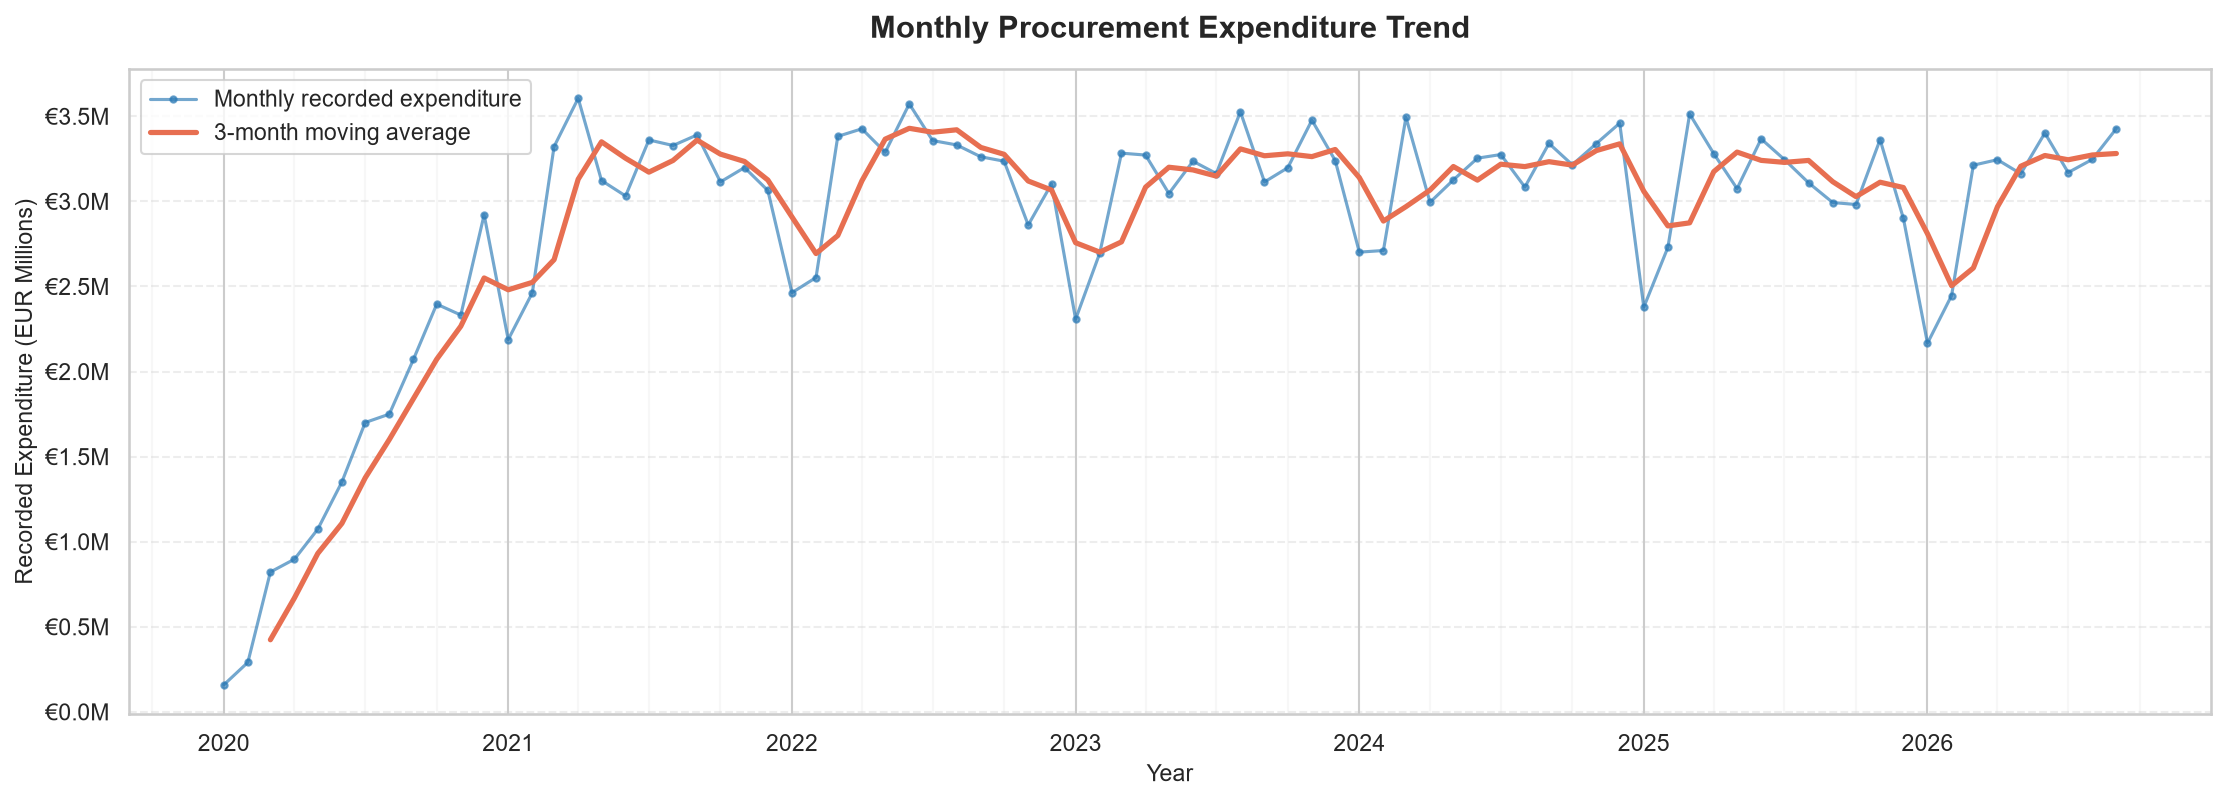

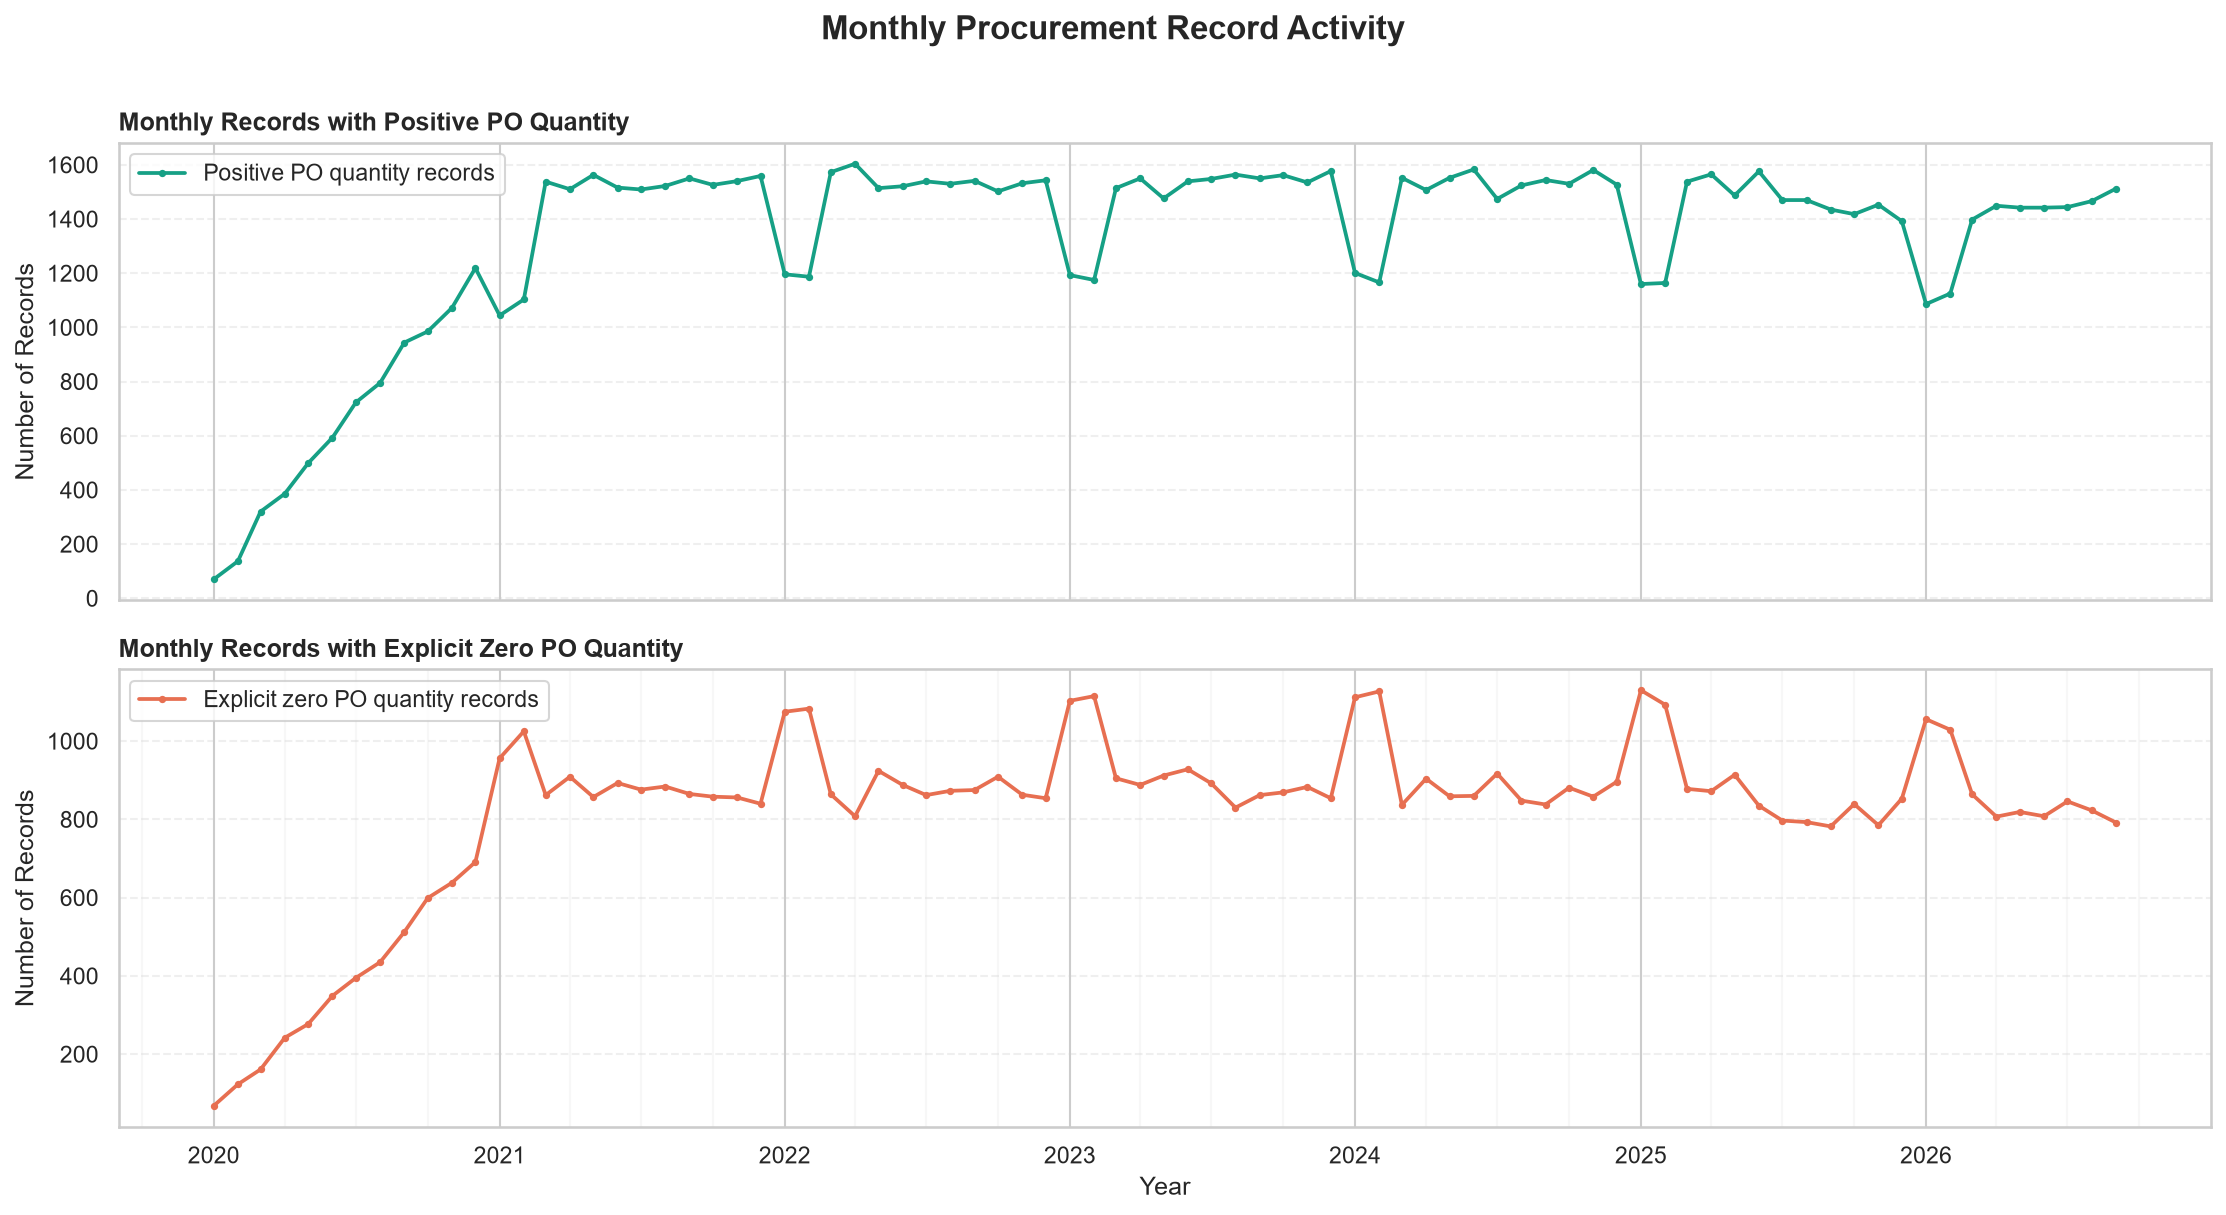

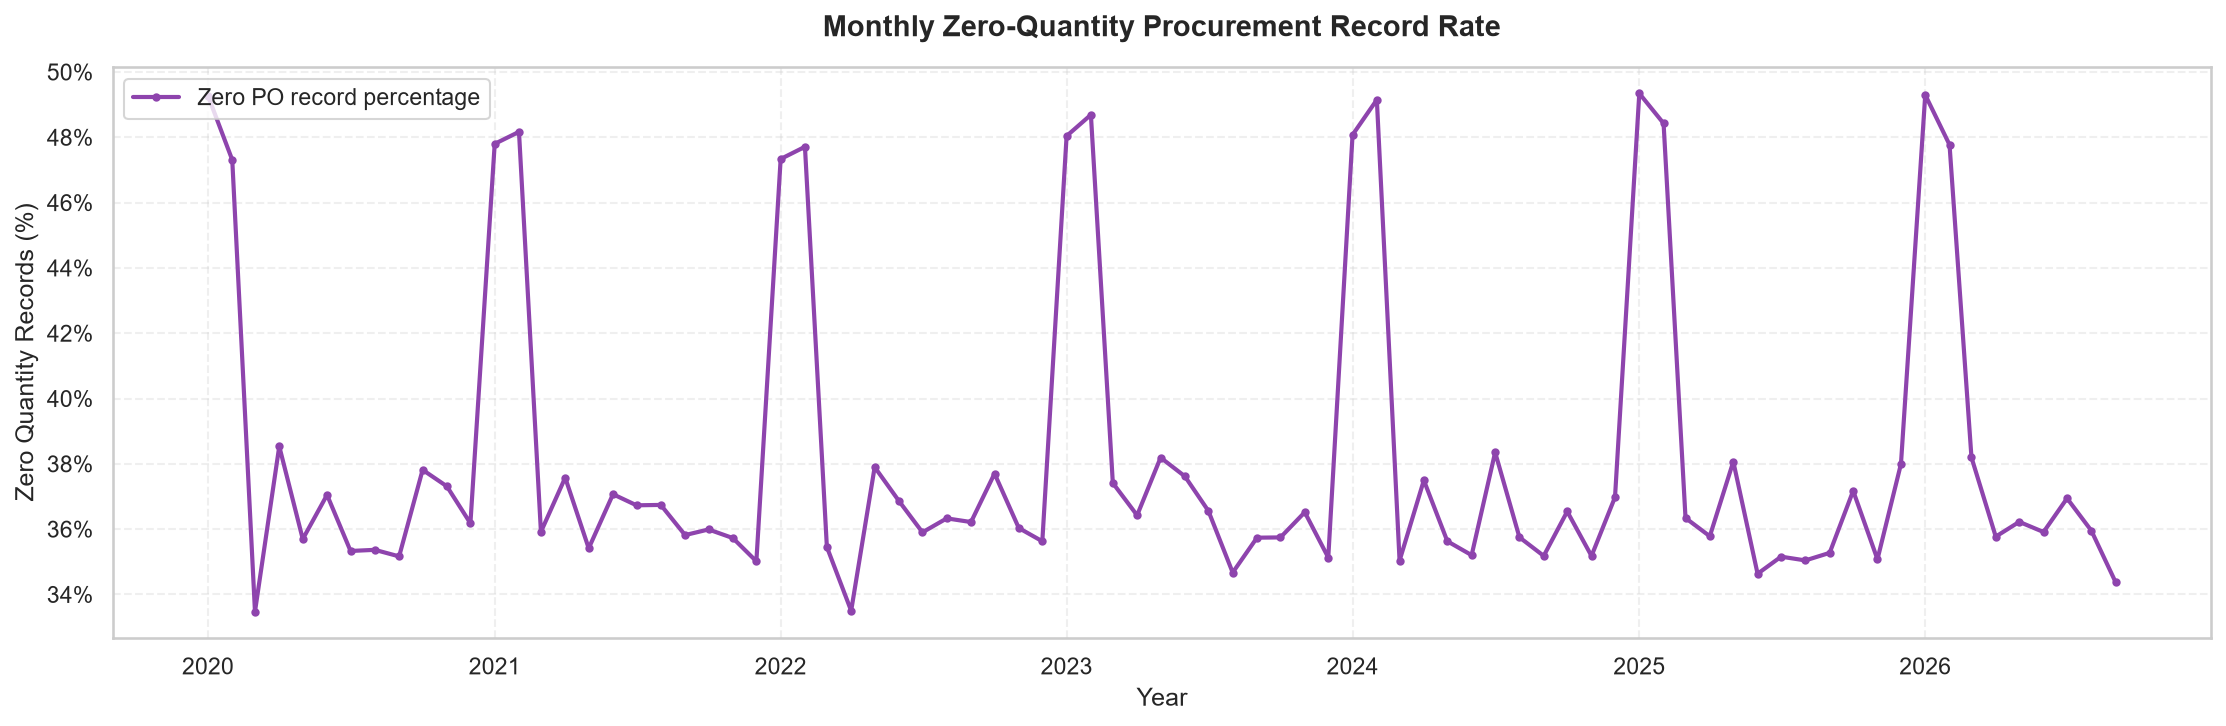

### Overall PO Quantity Status Summary

,Record Category,Total Records
0,Positive PO Quantity,108021
1,Explicit Zero PO Quantity,66442
2,Missing PO Quantity,175
3,Negative PO Quantity,0



### Business Interpretation

**1. Monthly Procurement Expenditure**

The first chart represents the total recorded procurement expenditure
in EUR for each month. The 3-month moving average helps identify the
underlying expenditure trend while reducing short-term fluctuations.

**2. Procurement Record Activity**

The second chart distinguishes records with positive PO quantities
from records that explicitly contain zero PO quantities.

These are record counts, not physical purchase quantities.

**3. Zero-Quantity Record Rate**

The third chart shows the percentage of known-quantity procurement
records with explicitly zero PO quantity.

Missing and negative PO quantities are excluded from this rate.

### Important Data Limitations

- Recorded EUR expenditure is not yet equivalent to fully validated spend.
- Duplicate business keys and price anomalies must be considered.
- Zero-quantity records must not be interpreted as missing months.
- Months without source rows are represented separately from
  explicit zero-quantity records.
- These charts represent procurement activity and expenditure,
  not validated raw-material unit-price movements.

### Next Investigation

The next analytical step is to validate procurement price fields,
measurement units, and currency conversions before constructing
historical material-level unit-price trends.


In [22]:
# ============================================================
# SECTION 3.8 — UNDERSTAND ACTUAL PROCUREMENT ACTIVITY
# Source: PostgreSQL | fact_procurement_monthly
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display, Markdown


# ------------------------------------------------------------
# 1. RETRIEVE PROCUREMENT DATA FROM POSTGRESQL
# ------------------------------------------------------------

# Monthly procurement activity and expenditure
procurement_patterns = sql_df("""
    SELECT
        month,

        COUNT(*) AS total_records,

        SUM(order_value_eur) AS eur_spend,

        COUNT(order_value_eur) AS records_with_eur_value,

        COUNT(*) FILTER (
            WHERE order_value_eur IS NULL
        ) AS missing_eur_value_rows,

        COUNT(*) FILTER (
            WHERE po_qty > 0
        ) AS positive_po_rows,

        COUNT(*) FILTER (
            WHERE po_qty = 0
        ) AS explicit_zero_po_rows,

        COUNT(*) FILTER (
            WHERE po_qty IS NULL
        ) AS missing_po_rows,

        COUNT(*) FILTER (
            WHERE po_qty < 0
        ) AS negative_po_rows,

        SUM(
            CASE WHEN po_qty > 0
            THEN po_qty ELSE 0 END
        ) AS total_positive_po_quantity

    FROM public.fact_procurement_monthly

    GROUP BY month
    ORDER BY month
""")


# Sample procurement records
procurement_monthly = sql_df("""
    SELECT *
    FROM public.fact_procurement_monthly
    LIMIT 5
""")


# Procurement distribution by plant
procurement_by_plant = sql_df("""
    SELECT
        plant_id,
        COUNT(*) AS total_records,
        SUM(order_value_eur) AS eur_spend

    FROM public.fact_procurement_monthly

    GROUP BY plant_id
    ORDER BY eur_spend DESC NULLS LAST
""")


# ------------------------------------------------------------
# 2. DISPLAY INITIAL DATA OBSERVATIONS
# ------------------------------------------------------------

display(Markdown("### Sample Procurement Records"))

display(procurement_monthly)


display(Markdown("### Monthly Procurement Summary"))

display(
    procurement_patterns.head(12).round(2)
)


display(Markdown("### Procurement Distribution by Plant"))

display(
    procurement_by_plant.round(2)
)


# ------------------------------------------------------------
# 3. PREPARE MONTHLY TIME SERIES
# ------------------------------------------------------------

activity = procurement_patterns.copy()

activity["month"] = pd.to_datetime(activity["month"])

# Normalize dates to the first day of each month
activity["month"] = (
    activity["month"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

activity = (
    activity
    .sort_values("month")
    .set_index("month")
)

# Generate a continuous monthly date index
# This helps identify months with no procurement records.
monthly_index = pd.date_range(
    start=activity.index.min(),
    end=activity.index.max(),
    freq="MS"
)

activity = activity.reindex(monthly_index)
activity.index.name = "month"

# IMPORTANT:
# Missing months are not treated as zero expenditure.
# Record counts are set to zero only to represent
# that no source rows were observed in that month.

count_columns = [
    "total_records",
    "records_with_eur_value",
    "missing_eur_value_rows",
    "positive_po_rows",
    "explicit_zero_po_rows",
    "missing_po_rows",
    "negative_po_rows",
    "total_positive_po_quantity"
]

activity[count_columns] = (
    activity[count_columns].fillna(0)
)


# ------------------------------------------------------------
# 4. GRAPH 1 — MONTHLY PROCUREMENT EXPENDITURE
# ------------------------------------------------------------

# Convert EUR into millions for better readability
activity["eur_spend_millions"] = (
    activity["eur_spend"] / 1_000_000
)

# Calculate 3-month moving average
activity["spend_3m_avg"] = (
    activity["eur_spend_millions"]
    .rolling(window=3, min_periods=3)
    .mean()
)

fig, ax = plt.subplots(
    figsize=(15, 5.5),
    dpi=150
)

# Actual monthly expenditure
ax.plot(
    activity.index,
    activity["eur_spend_millions"],
    color="#2878B5",
    linewidth=1.5,
    marker="o",
    markersize=3,
    alpha=0.65,
    label="Monthly recorded expenditure"
)

# Smoothed expenditure trend
ax.plot(
    activity.index,
    activity["spend_3m_avg"],
    color="#E76F51",
    linewidth=2.5,
    label="3-month moving average"
)

# EUR axis formatting
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, _: f"€{x:.1f}M"
    )
)

# Year-wise X-axis
ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax.xaxis.set_minor_locator(
    mdates.MonthLocator(
        bymonth=(4, 7, 10)
    )
)

ax.set_title(
    "Monthly Procurement Expenditure Trend",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Year",
    fontsize=11
)

ax.set_ylabel(
    "Recorded Expenditure (EUR Millions)",
    fontsize=11
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

ax.grid(
    which="minor",
    axis="x",
    alpha=0.15
)

ax.legend(
    loc="upper left",
    frameon=True
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. GRAPH 2 — PROCUREMENT ACTIVITY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 8),
    dpi=150,
    sharex=True
)


# Positive PO records
axes[0].plot(
    activity.index,
    activity["positive_po_rows"],
    color="#16A085",
    linewidth=1.8,
    marker="o",
    markersize=2.5,
    label="Positive PO quantity records"
)

axes[0].set_title(
    "Monthly Records with Positive PO Quantity",
    fontsize=12,
    fontweight="bold",
    loc="left"
)

axes[0].set_ylabel(
    "Number of Records"
)

axes[0].legend(
    loc="upper left"
)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


# Explicit zero PO records
axes[1].plot(
    activity.index,
    activity["explicit_zero_po_rows"],
    color="#E76F51",
    linewidth=1.8,
    marker="o",
    markersize=2.5,
    label="Explicit zero PO quantity records"
)

axes[1].set_title(
    "Monthly Records with Explicit Zero PO Quantity",
    fontsize=12,
    fontweight="bold",
    loc="left"
)

axes[1].set_ylabel(
    "Number of Records"
)

axes[1].set_xlabel(
    "Year"
)

axes[1].legend(
    loc="upper left"
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)


# Common date formatting
axes[1].xaxis.set_major_locator(
    mdates.YearLocator()
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

axes[1].xaxis.set_minor_locator(
    mdates.MonthLocator(
        bymonth=(4, 7, 10)
    )
)

axes[1].grid(
    which="minor",
    axis="x",
    alpha=0.15
)

fig.suptitle(
    "Monthly Procurement Record Activity",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. GRAPH 3 — ZERO QUANTITY RECORD PERCENTAGE
# ------------------------------------------------------------

# Only positive and explicit zero quantities are included.
# NULL and negative quantities are excluded from this denominator.

known_quantity_rows = (
    activity["positive_po_rows"]
    + activity["explicit_zero_po_rows"]
)

activity["zero_po_percentage"] = (
    activity["explicit_zero_po_rows"]
    .div(
        known_quantity_rows.replace(0, np.nan)
    )
    * 100
)


fig, ax = plt.subplots(
    figsize=(15, 5),
    dpi=150
)

ax.plot(
    activity.index,
    activity["zero_po_percentage"],
    color="#8E44AD",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Zero PO record percentage"
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, _: f"{x:.0f}%"
    )
)

ax.xaxis.set_major_locator(
    mdates.YearLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y")
)

ax.set_title(
    "Monthly Zero-Quantity Procurement Record Rate",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Zero Quantity Records (%)")

ax.grid(
    axis="both",
    linestyle="--",
    alpha=0.3
)

ax.legend(
    loc="upper left"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. QUANTITY STATUS SUMMARY
# ------------------------------------------------------------

quantity_summary = pd.DataFrame({
    "Record Category": [
        "Positive PO Quantity",
        "Explicit Zero PO Quantity",
        "Missing PO Quantity",
        "Negative PO Quantity"
    ],
    "Total Records": [
        int(activity["positive_po_rows"].sum()),
        int(activity["explicit_zero_po_rows"].sum()),
        int(activity["missing_po_rows"].sum()),
        int(activity["negative_po_rows"].sum())
    ]
})

display(
    Markdown("### Overall PO Quantity Status Summary")
)

display(quantity_summary)


# ------------------------------------------------------------
# 8. BUSINESS INTERPRETATION AND LIMITATIONS
# ------------------------------------------------------------

display(Markdown("""
### Business Interpretation

**1. Monthly Procurement Expenditure**

The first chart represents the total recorded procurement expenditure
in EUR for each month. The 3-month moving average helps identify the
underlying expenditure trend while reducing short-term fluctuations.

**2. Procurement Record Activity**

The second chart distinguishes records with positive PO quantities
from records that explicitly contain zero PO quantities.

These are record counts, not physical purchase quantities.

**3. Zero-Quantity Record Rate**

The third chart shows the percentage of known-quantity procurement
records with explicitly zero PO quantity.

Missing and negative PO quantities are excluded from this rate.

### Important Data Limitations

- Recorded EUR expenditure is not yet equivalent to fully validated spend.
- Duplicate business keys and price anomalies must be considered.
- Zero-quantity records must not be interpreted as missing months.
- Months without source rows are represented separately from
  explicit zero-quantity records.
- These charts represent procurement activity and expenditure,
  not validated raw-material unit-price movements.

### Next Investigation

The next analytical step is to validate procurement price fields,
measurement units, and currency conversions before constructing
historical material-level unit-price trends.
"""))


In [23]:
# Analytical configuration
PRICE_RECON_ABS_TOLERANCE = 0.01
PRICE_RECON_REL_TOLERANCE = 0.01
PRICE_P99_MIN_GROUP_SIZE = 20

# These are analysis settings, not mentor-approved business rules.


# --------------------------------------------------------------
# 1. BASE PROCUREMENT VALIDATION
# --------------------------------------------------------------

procurement_validation_metrics = sql_df(f"""

WITH material_ref AS (
    SELECT
        material_id,
        COUNT(*) AS material_master_rows,
        CASE
            WHEN COUNT(*) = 1 THEN MAX(base_uom)
        END AS base_uom
    FROM public.dim_material
    GROUP BY material_id
),

vendor_ref AS (
    SELECT
        vendor_id,
        COUNT(*) AS vendor_master_rows
    FROM public.dim_vendor
    GROUP BY vendor_id
),

bridge_ref AS (
    SELECT
        vendor_material_id,
        COUNT(*) AS bridge_rows,
        CASE
            WHEN COUNT(*) = 1 THEN MAX(vendor_id)
        END AS canonical_vendor_id
    FROM public.bridge_vendor_material
    GROUP BY vendor_material_id
),

fx_ref AS (
    SELECT
        month,
        to_currency,
        COUNT(*) AS fx_row_count,
        MAX(units_per_eur) AS units_per_eur
    FROM public.fact_fx_monthly
    WHERE from_currency = 'EUR'
    GROUP BY month, to_currency
),

fx_currency_ref AS (
    SELECT DISTINCT to_currency
    FROM public.fact_fx_monthly
    WHERE from_currency = 'EUR'
),

base AS (
    SELECT
        f.*,
        m.material_master_rows,
        m.base_uom,
        v.vendor_master_rows,
        b.bridge_rows,
        b.canonical_vendor_id,
        fx.fx_row_count,
        fx.units_per_eur,
        fxr.to_currency AS known_fx_currency

    FROM public.fact_procurement_monthly f

    LEFT JOIN material_ref m
        ON f.material_id = m.material_id

    LEFT JOIN vendor_ref v
        ON f.vendor_id = v.vendor_id

    LEFT JOIN bridge_ref b
        ON f.vendor_material_id = b.vendor_material_id

    LEFT JOIN fx_ref fx
        ON f.month = fx.month
       AND f.order_currency = fx.to_currency

    LEFT JOIN fx_currency_ref fxr
        ON f.order_currency = fxr.to_currency
),

-- --------------------------------------------------------------
-- 2. PRICE SPIKE ELIGIBILITY
-- --------------------------------------------------------------

price_eligible AS (
    SELECT
        procurement_id,
        material_id,
        order_currency,
        po_uom,
        unit_price_local

    FROM base

    WHERE unit_price_local > 0
      AND po_qty > 0
      AND material_master_rows = 1
      AND po_uom = base_uom
      AND order_currency ~ '^[A-Z]{{3}}$'
),

price_stats AS (
    SELECT
        material_id,
        order_currency,
        po_uom,
        COUNT(*) AS eligible_group_rows,

        PERCENTILE_CONT(0.99)
        WITHIN GROUP (
            ORDER BY unit_price_local
        ) AS p99_price

    FROM price_eligible

    GROUP BY
        material_id,
        order_currency,
        po_uom

    HAVING COUNT(*) >= {PRICE_P99_MIN_GROUP_SIZE}
),

price_spike_summary AS (
    SELECT
        COUNT(*) AS eligible_price_rows,

        COUNT(*) FILTER (
            WHERE p.unit_price_local > s.p99_price
        ) AS dq05_price_spike_candidates

    FROM price_eligible p

    INNER JOIN price_stats s
        ON p.material_id = s.material_id
       AND p.order_currency = s.order_currency
       AND p.po_uom = s.po_uom
),

-- --------------------------------------------------------------
-- 3. DUPLICATE BUSINESS KEY ANALYSIS
-- --------------------------------------------------------------

duplicate_groups AS (
    SELECT
        vendor_material_id,
        month,
        COUNT(*) AS group_rows

    FROM public.fact_procurement_monthly

    WHERE vendor_material_id IS NOT NULL
      AND month IS NOT NULL

    GROUP BY vendor_material_id, month

    HAVING COUNT(*) > 1
),

duplicate_summary AS (
    SELECT
        COUNT(*) AS duplicate_business_key_groups,

        COALESCE(
            SUM(group_rows - 1), 0
        ) AS dq08_duplicate_key_excess,

        COALESCE(
            SUM(group_rows), 0
        ) AS duplicate_affected_rows

    FROM duplicate_groups
)

-- --------------------------------------------------------------
-- 4. MAIN VALIDATION COUNTS
-- --------------------------------------------------------------

SELECT

    COUNT(*) AS total_procurement_rows,

    -- DQ01: Missing order value
    COUNT(*) FILTER (
        WHERE order_value_local IS NULL
    ) AS dq01_missing_order_value,

    -- DQ02: Missing PO quantity
    COUNT(*) FILTER (
        WHERE po_qty IS NULL
    ) AS dq02_missing_po_qty,

    -- DQ03: GR greater than PO, irrespective of unit
    COUNT(*) FILTER (
        WHERE po_qty IS NOT NULL
          AND gr_qty IS NOT NULL
          AND gr_qty > po_qty
    ) AS dq03_raw_numeric_candidates,

    -- DQ03: GR greater than PO only on comparable units
    COUNT(*) FILTER (
        WHERE material_master_rows = 1
          AND base_uom IS NOT NULL
          AND po_qty IS NOT NULL
          AND gr_qty IS NOT NULL
          AND po_uom = base_uom
          AND gr_uom = base_uom
          AND gr_qty > po_qty
    ) AS dq03_comparable_candidates,

    COUNT(*) FILTER (
        WHERE material_master_rows = 1
          AND base_uom IS NOT NULL
          AND po_qty IS NOT NULL
          AND gr_qty IS NOT NULL
          AND po_uom = base_uom
          AND gr_uom = base_uom
    ) AS dq03_eligible_comparable_rows,

    -- DQ04: Negative goods receipt
    COUNT(*) FILTER (
        WHERE gr_qty < 0
    ) AS dq04_negative_gr,

    COUNT(*) FILTER (
        WHERE gr_qty IS NOT NULL
    ) AS gr_observed_rows,

    -- DQ06: Non-standard currency format / alias
    COUNT(*) FILTER (
        WHERE order_currency IS NULL
           OR BTRIM(order_currency) = ''
           OR order_currency !~ '^[A-Z]{{3}}$'
    ) AS dq06_invalid_currency_format,

    -- Additional: No FX reference
    COUNT(*) FILTER (
        WHERE order_currency ~ '^[A-Z]{{3}}$'
          AND order_currency <> 'EUR'
          AND known_fx_currency IS NULL
    ) AS currency_without_fx_reference,

    -- Additional: Missing or ambiguous monthly FX
    COUNT(*) FILTER (
        WHERE order_currency ~ '^[A-Z]{{3}}$'
          AND order_currency <> 'EUR'
          AND (
              fx_row_count IS NULL
              OR fx_row_count <> 1
              OR units_per_eur IS NULL
              OR units_per_eur <= 0
          )
    ) AS missing_or_ambiguous_monthly_fx,

    COUNT(*) FILTER (
        WHERE order_currency ~ '^[A-Z]{{3}}$'
    ) AS fx_eligible_rows,

    COUNT(*) FILTER (
        WHERE order_currency = 'EUR'
           OR (
               order_currency ~ '^[A-Z]{{3}}$'
               AND fx_row_count = 1
               AND units_per_eur > 0
           )
    ) AS valid_fx_matched_rows,

    -- DQ07: Invalid vendor foreign key
    COUNT(*) FILTER (
        WHERE vendor_master_rows IS NULL
    ) AS dq07_invalid_vendor_fk,

    -- Vendor disagreement with canonical sourcing bridge
    COUNT(*) FILTER (
        WHERE bridge_rows = 1
          AND vendor_id IS DISTINCT FROM canonical_vendor_id
    ) AS vendor_bridge_mismatch_rows,

    COUNT(*) FILTER (
        WHERE bridge_rows IS NULL
    ) AS missing_sourcing_bridge_rows,

    COUNT(*) FILTER (
        WHERE bridge_rows > 1
    ) AS ambiguous_sourcing_bridge_rows,

    COUNT(*) FILTER (
        WHERE vendor_material_id IS NOT NULL
    ) AS sourcing_key_eligible_rows,

    COUNT(*) FILTER (
        WHERE vendor_material_id IS NOT NULL
          AND bridge_rows = 1
    ) AS unique_sourcing_match_rows,

    -- DQ08: Natural key denominator
    COUNT(*) FILTER (
        WHERE vendor_material_id IS NOT NULL
          AND month IS NOT NULL
    ) AS dq08_key_eligible_rows,

    -- DQ09: PO UOM mismatch
    COUNT(*) FILTER (
        WHERE material_master_rows = 1
          AND base_uom IS NOT NULL
          AND po_uom IS DISTINCT FROM base_uom
    ) AS dq09_po_uom_mismatches,

    -- DQ09: GR UOM mismatch
    COUNT(*) FILTER (
        WHERE material_master_rows = 1
          AND base_uom IS NOT NULL
          AND gr_uom IS DISTINCT FROM base_uom
    ) AS dq09_gr_uom_mismatches,

    COUNT(*) FILTER (
        WHERE material_master_rows = 1
          AND base_uom IS NOT NULL
          AND (
              po_uom IS DISTINCT FROM base_uom
              OR gr_uom IS DISTINCT FROM base_uom
          )
    ) AS dq09_unit_mismatch_rows,

    COUNT(*) FILTER (
        WHERE material_master_rows = 1
          AND base_uom IS NOT NULL
    ) AS dq09_eligible_material_rows,

    COUNT(*) FILTER (
        WHERE material_master_rows IS NULL
    ) AS unmatched_material_rows,

    -- DQ11: Zero quantity with positive spending
    COUNT(*) FILTER (
        WHERE po_qty = 0
          AND order_value_local > 0
    ) AS dq11_zero_qty_with_spend,

    COUNT(*) FILTER (
        WHERE po_qty = 0
    ) AS zero_po_rows,

    -- DQ12: Positive PO with zero same-month GR
    COUNT(*) FILTER (
        WHERE po_qty > 0
          AND gr_qty = 0
    ) AS dq12_zero_same_month_gr_candidates,

    COUNT(*) FILTER (
        WHERE po_qty > 0
    ) AS positive_po_rows,

    COUNT(*) FILTER (
        WHERE po_qty > 0
          AND gr_qty = 0
          AND material_master_rows = 1
          AND po_uom = base_uom
          AND gr_uom = base_uom
    ) AS dq12_unit_comparable_candidates,

    -- Unit-price derivation denominator
    COUNT(*) FILTER (
        WHERE po_qty > 0
          AND material_master_rows = 1
          AND po_uom = base_uom
    ) AS price_derivation_eligible_rows,

    COUNT(*) FILTER (
        WHERE po_qty > 0
          AND order_value_local IS NOT NULL
          AND material_master_rows = 1
          AND po_uom = base_uom
    ) AS price_derivable_rows,

    -- Price reconciliation eligible population
    COUNT(*) FILTER (
        WHERE po_qty > 0
          AND order_value_local IS NOT NULL
          AND unit_price_local IS NOT NULL
          AND material_master_rows = 1
          AND po_uom = base_uom
    ) AS price_reconciliation_eligible_rows,

    -- Price reconciliation mismatches
    COUNT(*) FILTER (
        WHERE po_qty > 0
          AND order_value_local IS NOT NULL
          AND unit_price_local IS NOT NULL
          AND material_master_rows = 1
          AND po_uom = base_uom
          AND ABS(
              unit_price_local -
              (order_value_local / NULLIF(po_qty, 0))
          ) > GREATEST(
              {PRICE_RECON_ABS_TOLERANCE},
              ABS(order_value_local / NULLIF(po_qty, 0))
                  * {PRICE_RECON_REL_TOLERANCE}
          )
    ) AS price_reconciliation_outliers,

    -- Negative PO quantity – additional independent check
    COUNT(*) FILTER (
        WHERE po_qty < 0
    ) AS negative_po_quantity_rows,

    -- Negative expenditure – additional independent check
    COUNT(*) FILTER (
        WHERE order_value_local < 0
    ) AS negative_order_value_rows,

    -- Duplicate statistics
    MAX(d.duplicate_business_key_groups)
        AS dq08_duplicate_business_key_groups,

    MAX(d.dq08_duplicate_key_excess)
        AS dq08_duplicate_key_excess,

    MAX(d.duplicate_affected_rows)
        AS dq08_duplicate_affected_rows,

    -- DQ05 statistics
    MAX(p.eligible_price_rows)
        AS dq05_eligible_price_rows,

    MAX(p.dq05_price_spike_candidates)
        AS dq05_price_spike_candidates

FROM base

CROSS JOIN duplicate_summary d
CROSS JOIN price_spike_summary p

""")

q = procurement_validation_metrics.iloc[0]

display(Markdown("## Procurement validation overview"))
display(procurement_validation_metrics.T.rename(columns={0: "Value"}))


## Procurement validation overview

,Value
total_procurement_rows,174638.0
dq01_missing_order_value,193.0
dq02_missing_po_qty,175.0
dq03_raw_numeric_candidates,10036.0
dq03_comparable_candidates,10024.0
dq03_eligible_comparable_rows,174282.0
dq04_negative_gr,186.0
gr_observed_rows,174638.0
dq06_invalid_currency_format,188.0
currency_without_fx_reference,0.0


Procurement activity exposed the central quality questions: missing values, receipt timing, unit comparability, currencies, duplicate aggregates, and structural gaps. The next table describes the commodity history itself so that later relationships compare like with like.

### 3.9 Understand historical commodity prices — `fact_commodity_monthly`

**Why am I investigating this?** Commodity history must be understood independently before it is used as an explanatory feature for procurement prices.

**What information will I examine?** commodity-month observations, index prices, index units and currencies, publication status, and benchmark region.

**Business meaning:**

This tells us how international commodity benchmarks move over time.
We can compare these movements against the procurement prices of the corresponding raw materials.
There are six commodity observations where the price is missing and the publication status is marked Missing

In [24]:
# Independent observation: fact_commodity_monthly
row_count, nulls = table_profile(
    "fact_commodity_monthly",
    TABLE_PURPOSES["fact_commodity_monthly"][0],
    TABLE_PURPOSES["fact_commodity_monthly"][1],
    categorical_columns=['index_currency', 'index_unit', 'publication_status', 'benchmark_region'],
    numeric_columns=['index_price'],
    date_columns=['month'],
)
display(Markdown(
    "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
    "and value patterns before any issue is declared. "
    "**Questions from this observation:** Are the distributions plausible for the stated grain, "
    "and do any fields need a business-rule explanation?"
))

### fact_commodity_monthly: monthly commodity benchmark history

**Expected grain:** commodity-month observation  
**Observed row count:** 1,053  
**Columns:** 7

**Sample records from PostgreSQL:**

,commodity_id,month,index_price,index_currency,index_unit,publication_status,benchmark_region
0,CMD01,2020-01-01,93.6494,USD,USD/metric_ton,Published,Europe
1,CMD01,2020-02-01,97.9637,USD,USD/metric_ton,Published,Europe
2,CMD01,2020-03-01,102.6706,USD,USD/metric_ton,Published,Europe
3,CMD01,2020-04-01,73.9617,USD,USD/metric_ton,Published,Europe
4,CMD01,2020-05-01,70.7425,USD,USD/metric_ton,Published,Europe


**Missing-value profile:**

,column_name,null_count,null_rate_pct
2,index_price_nulls,6,0.57
0,commodity_id_nulls,0,0.00
1,month_nulls,0,0.00
3,index_currency_nulls,0,0.00
4,index_unit_nulls,0,0.00
5,publication_status_nulls,0,0.00
6,benchmark_region_nulls,0,0.00


... (9 outputs left out)

,minimum,median,maximum
0,1.2422,329.9886,14105.9653


**Date coverage for `month`:**

,first_date,last_date
0,2020-01-01,2026-09-01


**What I observed:** The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. **Questions from this observation:** Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

,missing_prices,duplicate_commodity_month_excess,negative_prices,invalid_commodity_ids
0,6,0,0,0


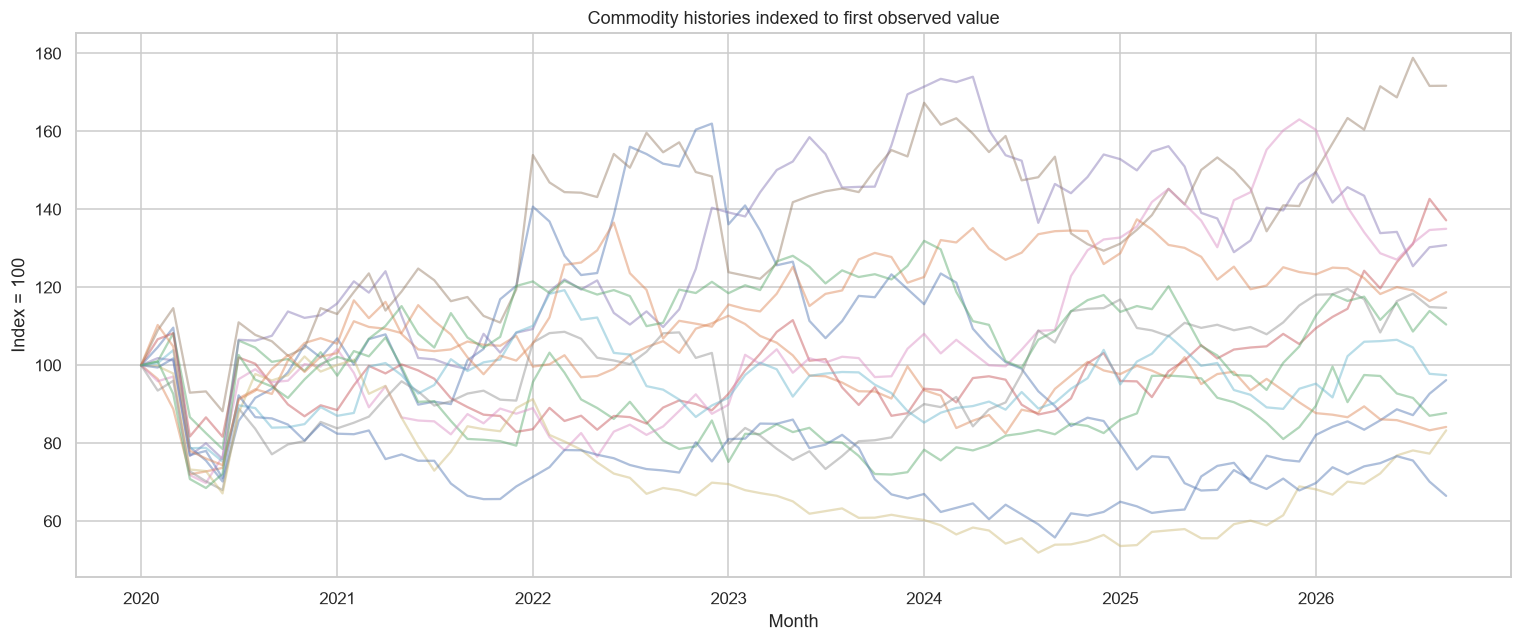

**Discovery:** 6 rows have missing index prices and 0 rows exceed the distinct commodity-month grain. **Business meaning:** raw commodity levels cannot be directly averaged across units; indexed or normalized series are safer for exploration. **Next:** FX history determines whether international procurement prices can be expressed in one currency.

In [25]:
commodity_history_checks = sql_df('''
    SELECT
        COUNT(*) FILTER (WHERE index_price IS NULL) AS missing_prices,
        COUNT(*) - COUNT(DISTINCT (commodity_id, month)) AS duplicate_commodity_month_excess,
        COUNT(*) FILTER (WHERE index_price < 0) AS negative_prices,
        COUNT(*) FILTER (WHERE commodity_id NOT IN (SELECT commodity_id FROM public.dim_commodity)) AS invalid_commodity_ids
    FROM public.fact_commodity_monthly
''')
commodity_trend = sql_df('''
    SELECT month, commodity_id, index_price
    FROM public.fact_commodity_monthly
    WHERE index_price IS NOT NULL
    ORDER BY month, commodity_id
''')
display(commodity_history_checks)
fig, ax = plt.subplots(figsize=(14, 6))
for commodity_id, group in commodity_trend.groupby("commodity_id"):
    first = group["index_price"].dropna().iloc[0] if group["index_price"].notna().any() else np.nan
    if pd.notna(first) and first != 0:
        ax.plot(group["month"], group["index_price"] / first * 100, alpha=0.45)
ax.set_title("Commodity histories indexed to first observed value")
ax.set_ylabel("Index = 100"); ax.set_xlabel("Month")
plt.tight_layout(); plt.show()
ch = commodity_history_checks.iloc[0]
log_table_observation("CMD-02", "fact_commodity_monthly", "commodity_id/month/index_price", "Is commodity history complete and unique at commodity-month grain?",
    "Commodity series show different units and market movements.",
    "Checked missing and negative prices, duplicate commodity-month keys, and commodity foreign keys.",
    f"{int(ch['missing_prices']):,} missing prices; {int(ch['duplicate_commodity_month_excess']):,} duplicate-key excess rows.",
    "Commodity price history needs unit and coverage controls before lagged comparison.",
    "High" if int(ch["duplicate_commodity_month_excess"]) else "Medium",
    "Reconcile duplicate observations and retain publication/benchmark metadata.",
    "Which publication status should be used for a historical analytical series?",
    "Confirmed Issue" if int(ch["duplicate_commodity_month_excess"]) or int(ch["missing_prices"]) else "Observed",
)
display(Markdown(
    f"**Discovery:** {int(ch['missing_prices']):,} rows have missing index prices and "
    f"{int(ch['duplicate_commodity_month_excess']):,} rows exceed the distinct commodity-month grain. "
    "**Business meaning:** raw commodity levels cannot be directly averaged across units; indexed or normalized series are safer for exploration. "
    "**Next:** FX history determines whether international procurement prices can be expressed in one currency."
))

Commodity history is a separate time series with its own coverage and unit rules. The next table investigates the exchange-rate evidence needed for EUR normalization.

### 3.10 Understand currency movements — `fact_fx_monthly`

**Why am I investigating this?** FX rates are needed to compare supplier prices quoted in different currencies on a common EUR basis.

**What information will I examine?** month, from/to currencies, units per EUR, rate type, and source label.
**Business meaning:** This file allows ECCO to convert procurement values into EUR so that prices from different suppliers can be compared on a common currency basis.

It also provides USD exchange rates for converting commodity benchmark prices.

In [26]:
# Independent observation: fact_fx_monthly
row_count, nulls = table_profile(
    "fact_fx_monthly",
    TABLE_PURPOSES["fact_fx_monthly"][0],
    TABLE_PURPOSES["fact_fx_monthly"][1],
    categorical_columns=['from_currency', 'to_currency', 'rate_type', 'source_label'],
    numeric_columns=['units_per_eur'],
    date_columns=['month'],
)
display(Markdown(
    "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
    "and value patterns before any issue is declared. "
    "**Questions from this observation:** Are the distributions plausible for the stated grain, "
    "and do any fields need a business-rule explanation?"
))

### fact_fx_monthly: monthly EUR exchange-rate normalization

**Expected grain:** month-currency rate  
**Observed row count:** 729  
**Columns:** 6

**Sample records from PostgreSQL:**

,month,from_currency,to_currency,units_per_eur,rate_type,source_label
0,2020-01-01,EUR,EUR,1.0,Monthly average,SYNTHETIC FX reference
1,2020-02-01,EUR,EUR,1.0,Monthly average,SYNTHETIC FX reference
2,2020-03-01,EUR,EUR,1.0,Monthly average,SYNTHETIC FX reference
3,2020-04-01,EUR,EUR,1.0,Monthly average,SYNTHETIC FX reference
4,2020-05-01,EUR,EUR,1.0,Monthly average,SYNTHETIC FX reference


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,month_nulls,0,0.0
1,from_currency_nulls,0,0.0
2,to_currency_nulls,0,0.0
3,units_per_eur_nulls,0,0.0
4,rate_type_nulls,0,0.0
5,source_label_nulls,0,0.0


... (9 outputs left out)

,minimum,median,maximum
0,1.0,10.4029,26873.5045


**Date coverage for `month`:**

,first_date,last_date
0,2020-01-01,2026-09-01


**What I observed:** The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. **Questions from this observation:** Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

In [27]:
fx_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT (month, from_currency, to_currency)) AS duplicate_fx_key_excess,
        COUNT(*) FILTER (WHERE units_per_eur <= 0) AS nonpositive_rates,
        COUNT(*) FILTER (WHERE from_currency <> 'EUR') AS unexpected_from_currency
    FROM public.fact_fx_monthly
''')
fx_coverage = sql_df('''
    SELECT to_currency, MIN(month) AS first_month, MAX(month) AS last_month, COUNT(*) AS observations
    FROM public.fact_fx_monthly
    GROUP BY to_currency
    ORDER BY to_currency
''')
display(fx_checks)
display(fx_coverage)
fx = fx_checks.iloc[0]
log_table_observation("FX-01", "fact_fx_monthly", "month/from_currency/to_currency", "Can each procurement currency be normalized using one monthly rate?",
    "FX data is directional and monthly.",
    "Checked duplicate keys, positive rate values, EUR direction, and currency-month coverage.",
    f"{int(fx['duplicate_fx_key_excess']):,} duplicate FX-key excess rows; {int(fx['nonpositive_rates']):,} non-positive rates.",
    "An invalid procurement currency or missing month-currency rate blocks reliable EUR conversion.",
    "High" if int(fx["duplicate_fx_key_excess"]) or int(fx["nonpositive_rates"]) else "Medium",
    "Use one validated EUR-to-currency rate per month and retain FX join flags.",
    "Is a missing rate an unavailable observation or an expected carry-forward rule?",
    "Confirmed Issue" if int(fx["duplicate_fx_key_excess"]) or int(fx["nonpositive_rates"]) else "Observed",
)
display(Markdown(
    f"**Discovery:** {int(fx['duplicate_fx_key_excess']):,} excess duplicate FX rows and "
    f"{int(fx['nonpositive_rates']):,} non-positive rates were found. "
    "**Business meaning:** EUR normalization is a data-quality dependency, not just a formatting step. "
    "**Next:** supplier performance must be understood at its own quarterly vendor-plant grain."
))

,duplicate_fx_key_excess,nonpositive_rates,unexpected_from_currency
0,0,0,0


,to_currency,first_month,last_month,observations
0,BRL,2020-01-01,2026-09-01,81
1,CNY,2020-01-01,2026-09-01,81
2,EUR,2020-01-01,2026-09-01,81
3,IDR,2020-01-01,2026-09-01,81
4,INR,2020-01-01,2026-09-01,81
5,THB,2020-01-01,2026-09-01,81
6,TRY,2020-01-01,2026-09-01,81
7,USD,2020-01-01,2026-09-01,81
8,VND,2020-01-01,2026-09-01,81


**Discovery:** 0 excess duplicate FX rows and 0 non-positive rates were found. **Business meaning:** EUR normalization is a data-quality dependency, not just a formatting step. **Next:** supplier performance must be understood at its own quarterly vendor-plant grain.

FX evidence establishes whether prices can be compared across currencies. The final independent table is supplier performance, which must not be mistaken for SKU-level data.

### 3.11 Understand supplier reliability / tells us how well suppliers perform. — `fact_vendor_performance_quarterly`

**Why am I investigating this?** Supplier performance provides delivery, quality, lead-time, price-variance, and capacity context, but its grain is quarterly vendor-plant rather than material-month.

**What information will I examine?** performance IDs, vendor and plant keys, quarter boundaries, delivery lines, on-time delivery, defect rate, lead time, price variance, and capacity utilization.

**Business meaning:** The cheapest supplier may not necessarily be the best supplier.

In [28]:
# Independent observation: fact_vendor_performance_quarterly
row_count, nulls = table_profile(
    "fact_vendor_performance_quarterly",
    TABLE_PURPOSES["fact_vendor_performance_quarterly"][0],
    TABLE_PURPOSES["fact_vendor_performance_quarterly"][1],
    categorical_columns=[],
    numeric_columns=['delivery_lines', 'on_time_delivery_pct', 'defect_rate_pct', 'avg_actual_lead_days', 'price_variance_pct', 'capacity_utilization_pct'],
    date_columns=['quarter_start', 'quarter_end'],
)
display(Markdown(
    "**What I observed:** The output above shows the actual PostgreSQL sample, completeness, "
    "and value patterns before any issue is declared. "
    "**Questions from this observation:** Are the distributions plausible for the stated grain, "
    "and do any fields need a business-rule explanation?"
))

### fact_vendor_performance_quarterly: quarterly supplier delivery and quality context

**Expected grain:** vendor-plant-quarter observation  
**Observed row count:** 78,570  
**Columns:** 11

**Sample records from PostgreSQL:**

,performance_id,vendor_id,plant_id,quarter_start,quarter_end,delivery_lines,on_time_delivery_pct,defect_rate_pct,avg_actual_lead_days,price_variance_pct,capacity_utilization_pct
0,PER00001-01,100112,1001,2020-01-01,2020-03-01,74,87.2,1.60,18,2.31,48.1
1,PER00001-02,100112,1001,2020-04-01,2020-06-01,8,85.0,0.26,14,-0.34,78.1
2,PER00001-03,100112,1001,2020-07-01,2020-09-01,34,90.2,1.48,18,1.30,80.6
3,PER00001-04,100112,1001,2020-10-01,2020-12-01,84,89.2,0.00,15,0.90,95.9
4,PER00001-05,100112,1001,2021-01-01,2021-03-01,35,94.8,1.36,19,0.37,72.7


**Missing-value profile:**

,column_name,null_count,null_rate_pct
0,performance_id_nulls,0,0.0
1,vendor_id_nulls,0,0.0
2,plant_id_nulls,0,0.0
3,quarter_start_nulls,0,0.0
4,quarter_end_nulls,0,0.0
5,delivery_lines_nulls,0,0.0
6,on_time_delivery_pct_nulls,0,0.0
7,defect_rate_pct_nulls,0,0.0
8,avg_actual_lead_days_nulls,0,0.0
9,price_variance_pct_nulls,0,0.0


... (13 outputs left out)

,first_date,last_date
0,2020-01-01,2026-07-01


**Date coverage for `quarter_end`:**

,first_date,last_date
0,2020-03-01,2026-09-01


**What I observed:** The output above shows the actual PostgreSQL sample, completeness, and value patterns before any issue is declared. **Questions from this observation:** Are the distributions plausible for the stated grain, and do any fields need a business-rule explanation?

,duplicate_vendor_plant_quarter_excess,invalid_vendor_ids,invalid_plant_ids,invalid_on_time,invalid_defect_rate,invalid_capacity,invalid_quarter_periods
0,63342,0,0,0,0,0,0


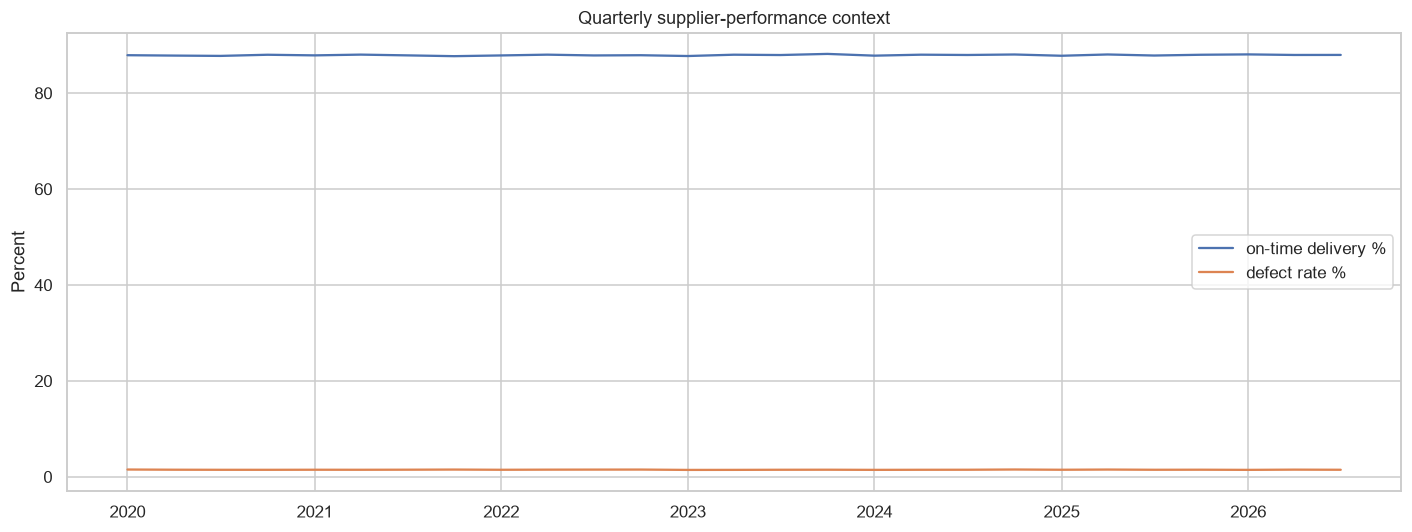

**Discovery:** 63,342 rows exceed the vendor-plant-quarter grain and 0 vendor foreign-key mismatches were found. **Business meaning:** supplier performance can inform procurement analysis, but it cannot be attached to every SKU row without a deliberate aggregation and leakage rule. **Next:** consolidate the independent table findings before building relationships.

In [29]:
performance_checks = sql_df('''
    SELECT
        COUNT(*) - COUNT(DISTINCT (vendor_id, plant_id, quarter_start)) AS duplicate_vendor_plant_quarter_excess,
        COUNT(*) FILTER (WHERE vendor_id NOT IN (SELECT vendor_id FROM public.dim_vendor)) AS invalid_vendor_ids,
        COUNT(*) FILTER (WHERE plant_id NOT IN (SELECT plant_id FROM public.dim_plant)) AS invalid_plant_ids,
        COUNT(*) FILTER (WHERE on_time_delivery_pct < 0 OR on_time_delivery_pct > 100) AS invalid_on_time,
        COUNT(*) FILTER (WHERE defect_rate_pct < 0 OR defect_rate_pct > 100) AS invalid_defect_rate,
        COUNT(*) FILTER (WHERE capacity_utilization_pct < 0 OR capacity_utilization_pct > 100) AS invalid_capacity,
        COUNT(*) FILTER (WHERE quarter_end < quarter_start) AS invalid_quarter_periods
    FROM public.fact_vendor_performance_quarterly
''')
performance_trend = sql_df('''
    SELECT quarter_start, AVG(on_time_delivery_pct) AS avg_on_time_delivery,
           AVG(defect_rate_pct) AS avg_defect_rate
    FROM public.fact_vendor_performance_quarterly
    GROUP BY quarter_start
    ORDER BY quarter_start
''')
display(performance_checks)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(performance_trend["quarter_start"], performance_trend["avg_on_time_delivery"], label="on-time delivery %")
ax.plot(performance_trend["quarter_start"], performance_trend["avg_defect_rate"], label="defect rate %")
ax.set_title("Quarterly supplier-performance context")
ax.set_ylabel("Percent"); ax.legend()
plt.tight_layout(); plt.show()
sp = performance_checks.iloc[0]
log_table_observation("PERF-01", "fact_vendor_performance_quarterly", "vendor_id/plant_id/quarter_start", "Does supplier performance have a stable relationship-level grain?",
    "Performance rows contain vendor, plant, and quarter but no material_id.",
    "Checked duplicate vendor-plant-quarter combinations, foreign keys, KPI ranges, and quarter ordering.",
    f"{int(sp['duplicate_vendor_plant_quarter_excess']):,} duplicate-grain excess rows; {int(sp['invalid_vendor_ids']):,} invalid vendor IDs.",
    "Raw performance must be aggregated before it is used beside monthly procurement; a material-level join would create many-to-many expansion.",
    "High" if int(sp["duplicate_vendor_plant_quarter_excess"]) or int(sp["invalid_vendor_ids"]) else "Medium",
    "Aggregate performance by vendor/plant/quarter and document the weighting rule before integration.",
    "Should performance be used as supplier context only, or is a material-level relationship available elsewhere?",
    "Confirmed Issue" if int(sp["duplicate_vendor_plant_quarter_excess"]) else "Business Rule Confirmation Required",
)
display(Markdown(
    f"**Discovery:** {int(sp['duplicate_vendor_plant_quarter_excess']):,} rows exceed the vendor-plant-quarter grain and "
    f"{int(sp['invalid_vendor_ids']):,} vendor foreign-key mismatches were found. "
    "**Business meaning:** supplier performance can inform procurement analysis, but it cannot be attached to every SKU row without a deliberate aggregation and leakage rule. "
    "**Next:** consolidate the independent table findings before building relationships."
))

The independent table research is complete. Supplier performance closes the table sequence; the investigation now moves from table understanding to consolidated findings and relationship validation.

## STAGE 04 — Consolidate table-wise observations before joining tables

**Why am I investigating this?** Joining too early can hide whether a problem belongs to a source table, a relationship, or an analytical assumption.

**What information did I examine?** The investigation log accumulated during the individual table reviews, including evidence, status, severity, remediation ownership, and mentor clarification.

**What did I discover?** The most important unresolved questions concern procurement grain, canonical vendor identity, units, invalid currency aliases, contract validity, structural missing months, commodity exposure assumptions, and supplier-performance grain.

In [30]:
# 6. Table-wise findings and the running investigation/evidence log
investigation_log_df = pd.DataFrame(investigation_log)
display(investigation_log_df[[
    "investigation_id", "source", "field_or_relationship", "finding",
    "severity", "status", "recommended_action", "mentor_clarification"
]])
table_findings = (
    investigation_log_df.groupby("source", as_index=False)
    .agg(
        investigations=("investigation_id", "count"),
        highest_severity=("severity", lambda values: next((s for s in ["High", "Medium", "Low"] if s in set(values)), "Low")),
        statuses=("status", lambda values: ", ".join(sorted(set(values)))),
        main_questions=("mentor_clarification", lambda values: " | ".join(values.head(2))),
    )
)
display(table_findings)
display(Markdown(
    "**Transition:** the table-wise investigation tells us what each source contains and where uncertainty begins. "
    "The next stage tests the actual business paths one relationship at a time."
))

,investigation_id,source,field_or_relationship,finding,severity,status,recommended_action,mentor_clarification
0,MAT-01,dim_material,material_id,No duplicate IDs or missing descriptions were found.,Low,Observed,Resolve duplicate IDs or descriptions before using the master as a one-row-per-material dimension.,Confirm the approved list of material units and whether inactive materials may still appear in historical procurement.
1,VEN-01,dim_vendor,preferred_currency,Currency coverage is a prerequisite for comparable international supplier prices.,Low,Observed,Provide or validate FX coverage before normalizing vendor prices.,"Confirm whether preferred currency is contractual, operational, or only a master-data default."
2,PLT-01,dim_plant,purch_org_id/local_currency,Plant-level joins need explicit orphan and currency checks.,Low,Observed,Resolve unmatched plants and document local-currency FX coverage.,Confirm whether a plant may change purchasing organization or local currency over time.
3,ORG-01,dim_purchasing_org,purch_org_id,Organizational ownership is a master-data dependency for plant-level analysis.,Low,Observed,Maintain one descriptive row per organization and validate plant assignments.,Confirm whether organization descriptions are historical or current-only.
4,COM-01,dim_commodity,commodity_id/index_unit,Commodity levels cannot be averaged directly when units differ; mapping and normalization are required.,Low,Observed,Document unit semantics and coverage before constructing exposure features.,Confirm which benchmark source and unit should be treated as authoritative for each material group.
5,SRC-01,bridge_vendor_material,vendor_material_id/contract dates,"The bridge is the canonical relationship, but any invalid keys or contract dates can affect procurement attribution.",Medium,Observed,Resolve master-data keys and validate contract periods before using the bridge for price attribution.,Confirm whether expired approval relationships remain valid for historical procurement.
6,EXP-01,bridge_material_commodity,exposure_weight/lag_months,"Exposure weights and lags are analytical assumptions, not proof of causality.",Medium,Business Rule Confirmation Required,Validate mapping governance and preserve confidence/lag fields in any analytical layer.,Confirm whether three mappings per material and the supplied lag range are business rules or synthetic design choices.
7,CMD-02,fact_commodity_monthly,commodity_id/month/index_price,Commodity price history needs unit and coverage controls before lagged comparison.,Medium,Confirmed Issue,Reconcile duplicate observations and retain publication/benchmark metadata.,Which publication status should be used for a historical analytical series?
8,FX-01,fact_fx_monthly,month/from_currency/to_currency,An invalid procurement currency or missing month-currency rate blocks reliable EUR conversion.,Medium,Observed,Use one validated EUR-to-currency rate per month and retain FX join flags.,Is a missing rate an unavailable observation or an expected carry-forward rule?
9,PERF-01,fact_vendor_performance_quarterly,vendor_id/plant_id/quarter_start,Raw performance must be aggregated before it is used beside monthly procurement; a material-level join would create many-to-many expansion.,High,Confirmed Issue,Aggregate performance by vendor/plant/quarter and document the weighting rule before integration.,"Should performance be used as supplier context only, or is a material-level relationship available elsewhere?"


,source,investigations,highest_severity,statuses,main_questions
0,bridge_material_commodity,1,Medium,Business Rule Confirmation Required,Confirm whether three mappings per material and the supplied lag range are business rules or synthetic design choices.
1,bridge_vendor_material,1,Medium,Observed,Confirm whether expired approval relationships remain valid for historical procurement.
2,dim_commodity,1,Low,Observed,Confirm which benchmark source and unit should be treated as authoritative for each material group.
3,dim_material,1,Low,Observed,Confirm the approved list of material units and whether inactive materials may still appear in historical procurement.
4,dim_plant,1,Low,Observed,Confirm whether a plant may change purchasing organization or local currency over time.
5,dim_purchasing_org,1,Low,Observed,Confirm whether organization descriptions are historical or current-only.
6,dim_vendor,1,Low,Observed,"Confirm whether preferred currency is contractual, operational, or only a master-data default."
7,fact_commodity_monthly,1,Medium,Confirmed Issue,Which publication status should be used for a historical analytical series?
8,fact_fx_monthly,1,Medium,Observed,Is a missing rate an unavailable observation or an expected carry-forward rule?
9,fact_vendor_performance_quarterly,1,High,Confirmed Issue,"Should performance be used as supplier context only, or is a material-level relationship available elsewhere?"


**Transition:** the table-wise investigation tells us what each source contains and where uncertainty begins. The next stage tests the actual business paths one relationship at a time.

## STAGE 05 — Research and validate relationships step by step

**Relationship 1:** material → procurement  
**Relationship 2:** material → sourcing bridge → vendor/plant → procurement  
**Relationship 3:** material → commodity exposure → commodity master  
**Relationship 4:** commodity master → commodity history  
**Relationship 5:** procurement → monthly FX  
**Relationship 6:** procurement vendor/plant → quarterly performance

For each relationship, I will state why the join is needed, identify the key and expected cardinality, execute PostgreSQL validation, compare matched and unmatched records, check row multiplication, interpret the result, and record the next action.

In [31]:
# 7. Relationship 1: material master to procurement fact
material_procurement = sql_df('''
    SELECT
        COUNT(*) AS procurement_rows,
        COUNT(*) FILTER (WHERE m.material_id IS NOT NULL) AS matched_rows,
        COUNT(*) FILTER (WHERE m.material_id IS NULL) AS unmatched_rows,
        COUNT(DISTINCT f.material_id) AS distinct_fact_materials,
        COUNT(DISTINCT m.material_id) AS distinct_matched_materials
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.dim_material m ON m.material_id = f.material_id
''')
material_join_sample = sql_df('''
    SELECT f.material_id, f.month, f.po_uom, m.base_uom, m.material_group_name
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.dim_material m ON m.material_id = f.material_id
    LIMIT 10
''')
display(material_procurement)
display(material_join_sample)
r1 = material_procurement.iloc[0]
add_log("REL-01", "STAGE 05", "fact_procurement_monthly → dim_material", "material_id",
    "Do procurement rows reference a unique material master row?",
    "The procurement fact contains a material_id used for product interpretation.",
    "Left-joined the fact to the dimension and compared row counts and matched IDs.",
    f"{int(r1['unmatched_rows']):,} unmatched procurement rows; {int(r1['procurement_rows']):,} total rows.",
    "Material join coverage is required before using groups, base units, active dates, or descriptions.",
    "High" if int(r1["unmatched_rows"]) else "Low",
    "Resolve unmatched material IDs and check for dimension duplicates before joining.",
    "Is material_id or material_7 the authoritative business key?",
    "Confirmed Issue" if int(r1["unmatched_rows"]) else "Observed")
display(Markdown(
    f"**Relationship result:** {int(r1['matched_rows']):,} of {int(r1['procurement_rows']):,} procurement rows matched the material master. "
    f"Unmatched rows: {int(r1['unmatched_rows']):,}. **Business meaning:** material attributes can only be trusted for matched rows. "
    "**Next:** the sourcing bridge is needed to resolve supplier and plant identity."
))

,procurement_rows,matched_rows,unmatched_rows,distinct_fact_materials,distinct_matched_materials
0,174638,174638,0,1200,1200


,material_id,month,po_uom,base_uom,material_group_name
0,C22001300004,2020-08-01,PAA,PAA,Shoe lace
1,C22001300004,2020-09-01,PAA,PAA,Shoe lace
2,C22001300004,2020-10-01,PAA,PAA,Shoe lace
3,C22001300004,2020-11-01,PAA,PAA,Shoe lace
4,C22001300004,2020-12-01,PAA,PAA,Shoe lace
5,C22001300004,2021-01-01,PAA,PAA,Shoe lace
6,C22001300004,2021-02-01,PAA,PAA,Shoe lace
7,C22001300004,2021-03-01,PAA,PAA,Shoe lace
8,C22001300004,2021-05-01,PAA,PAA,Shoe lace
9,C22001300004,2021-06-01,PAA,PAA,Shoe lace


**Relationship result:** 174,638 of 174,638 procurement rows matched the material master. Unmatched rows: 0. **Business meaning:** material attributes can only be trusted for matched rows. **Next:** the sourcing bridge is needed to resolve supplier and plant identity.

In [32]:
# 8. Relationship 2: sourcing bridge to vendor, material, plant, and procurement
sourcing_join = sql_df('''
    SELECT
        COUNT(*) AS procurement_rows,
        COUNT(*) FILTER (WHERE b.vendor_material_id IS NOT NULL) AS bridge_matched_rows,
        COUNT(*) FILTER (WHERE v.vendor_id IS NOT NULL) AS vendor_matched_rows,
        COUNT(*) FILTER (WHERE p.plant_id IS NOT NULL) AS plant_matched_rows,
        COUNT(*) FILTER (WHERE b.approved_from <= f.month
                              AND (b.approved_to IS NULL OR f.month <= b.approved_to)) AS contract_valid_rows,
        COUNT(*) FILTER (WHERE f.vendor_id <> b.vendor_id) AS reported_vendor_mismatch_rows
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
    LEFT JOIN public.dim_vendor v ON v.vendor_id = b.vendor_id
    LEFT JOIN public.dim_plant p ON p.plant_id = b.plant_id
''')
sourcing_expansion = sql_df('''
    SELECT f.procurement_id, COUNT(*) AS joined_rows
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
    GROUP BY f.procurement_id
    HAVING COUNT(*) > 1
    LIMIT 20
''')
display(sourcing_join)
display(sourcing_expansion)
r2 = sourcing_join.iloc[0]
add_log("REL-02", "STAGE 05", "fact_procurement_monthly → bridge_vendor_material → dim_vendor/dim_plant",
    "vendor_material_id/vendor_id/plant_id/contract dates",
    "Does the canonical sourcing relationship identify the supplier and plant without multiplying procurement rows?",
    "The bridge is intended to be the canonical path; the fact also carries a reported vendor_id.",
    "Joined through vendor_material_id, checked vendor/plant coverage, contract validity, mismatches, and expansion.",
    f"{int(r2['reported_vendor_mismatch_rows']):,} reported-vendor mismatches; {int(r2['contract_valid_rows']):,} rows within approval periods.",
    "Use the bridge vendor as canonical, retain fact vendor mismatch as a quality flag, and do not assume every row is contract-valid.",
    "High", "Resolve invalid vendor keys and preserve contract-validity flags in the analytical layer.",
    "How should procurement posted outside contract validity be interpreted?",
    "Confirmed Issue" if int(r2["reported_vendor_mismatch_rows"]) else "Under Investigation")
display(Markdown(
    f"**Relationship result:** {int(r2['bridge_matched_rows']):,} procurement rows matched the sourcing bridge and "
    f"{int(r2['reported_vendor_mismatch_rows']):,} disagreed with the bridge vendor. "
    f"The join produced {len(sourcing_expansion):,} sampled procurement IDs with expansion. "
    "**Business meaning:** canonical sourcing identity must be separated from denormalized source fields before supplier analysis."
))

,procurement_rows,bridge_matched_rows,vendor_matched_rows,plant_matched_rows,contract_valid_rows,reported_vendor_mismatch_rows
0,174638,174638,174638,174638,174638,198


,procurement_id,joined_rows


**Relationship result:** 174,638 procurement rows matched the sourcing bridge and 198 disagreed with the bridge vendor. The join produced 0 sampled procurement IDs with expansion. **Business meaning:** canonical sourcing identity must be separated from denormalized source fields before supplier analysis.

In [33]:
# 9. Relationships 3 and 4: material exposure, commodity master, and monthly history
exposure_join = sql_df('''
    SELECT
        COUNT(DISTINCT m.material_id) AS material_master_count,
        COUNT(DISTINCT b.material_id) AS mapped_material_count,
        COUNT(*) FILTER (WHERE m.material_id IS NULL) AS invalid_material_mapping_rows,
        COUNT(*) FILTER (WHERE c.commodity_id IS NULL) AS invalid_commodity_mapping_rows,
        COUNT(*) FILTER (WHERE ABS(w.weight_sum - 1) > 0.000001) AS invalid_weight_groups
    FROM public.bridge_material_commodity b
    LEFT JOIN public.dim_material m ON m.material_id = b.material_id
    LEFT JOIN public.dim_commodity c ON c.commodity_id = b.commodity_id
    LEFT JOIN (
        SELECT material_id, SUM(exposure_weight) AS weight_sum
        FROM public.bridge_material_commodity
        GROUP BY material_id
    ) w ON w.material_id = b.material_id
''')
commodity_history_join = sql_df('''
    SELECT
        COUNT(*) AS mapping_rows,
        COUNT(cm.commodity_id) AS history_matched_rows,
        COUNT(*) FILTER (WHERE cm.index_price IS NULL) AS missing_price_rows
    FROM public.bridge_material_commodity b
    LEFT JOIN public.fact_commodity_monthly cm
      ON cm.commodity_id = b.commodity_id
''')
display(exposure_join)
display(commodity_history_join)
r3 = exposure_join.iloc[0]
r4 = commodity_history_join.iloc[0]
add_log("REL-03", "STAGE 05", "dim_material → bridge_material_commodity → dim_commodity", "material_id/commodity_id/exposure_weight",
    "Does every material have valid, weighted commodity exposure mappings?",
    "Materials are mapped to one or more commodity benchmarks.",
    "Checked dimension matches, mapping coverage, and per-material weight totals.",
    f"{int(r3['mapped_material_count']):,} mapped materials; {int(r3['invalid_weight_groups']):,} invalid weight groups.",
    "Exposure mappings are usable only when keys and totals are valid.",
    "High" if int(r3["invalid_weight_groups"]) else "Medium",
    "Preserve weights, lags, confidence, and validity dates; do not infer missing exposure silently.",
    "Are mappings approved business assumptions or generated analytical proxies?",
    "Confirmed Issue" if int(r3["invalid_weight_groups"]) else "Business Rule Confirmation Required")
add_log("REL-04", "STAGE 05", "dim_commodity → fact_commodity_monthly", "commodity_id/month/index_price",
    "Does every mapped commodity have usable monthly history?",
    "The commodity master provides definitions while the fact provides historical observations.",
    "Left-joined mappings to monthly history and checked matched and missing-price rows.",
    f"{int(r4['missing_price_rows']):,} mapping-history rows with missing prices.",
    "Commodity coverage must be measured before lagged correlation analysis.",
    "Medium", "Create commodity coverage flags and document missing-price treatment.",
    "Should unpublished prices be excluded or represented as missing?",
    "Under Investigation")
display(Markdown(
    f"**Relationship result:** {int(r3['mapped_material_count']):,} materials have mappings; "
    f"{int(r3['invalid_weight_groups']):,} weight groups need review. "
    f"Commodity history matched {int(r4['history_matched_rows']):,} mapping-history rows, with "
    f"{int(r4['missing_price_rows']):,} missing-price rows. **Next:** validate procurement-to-FX coverage."
))

,material_master_count,mapped_material_count,invalid_material_mapping_rows,invalid_commodity_mapping_rows,invalid_weight_groups
0,1200,1200,0,0,0


,mapping_rows,history_matched_rows,missing_price_rows
0,291600,291600,1900


**Relationship result:** 1,200 materials have mappings; 0 weight groups need review. Commodity history matched 291,600 mapping-history rows, with 1,900 missing-price rows. **Next:** validate procurement-to-FX coverage.

In [34]:
# 10. Relationship 5: procurement to monthly FX
fx_join = sql_df('''
    SELECT
        COUNT(*) AS procurement_rows,
        COUNT(fx.month) AS matched_fx_rows,
        COUNT(*) FILTER (WHERE fx.month IS NULL) AS missing_fx_rows,
        COUNT(*) FILTER (WHERE f.order_currency NOT IN (
            SELECT DISTINCT to_currency FROM public.fact_fx_monthly
        )) AS invalid_currency_rows,
        COUNT(*) FILTER (WHERE f.order_currency = 'EURO') AS EURO_alias_rows
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.fact_fx_monthly fx
      ON fx.month = f.month
     AND fx.from_currency = 'EUR'
     AND fx.to_currency = f.order_currency
''')
fx_recovery = sql_df('''
    SELECT
        COUNT(*) AS EURO_rows,
        COUNT(*) FILTER (WHERE fx.to_currency IS NOT NULL) AS recovered_by_contract_currency
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
    LEFT JOIN public.fact_fx_monthly fx
      ON fx.month = f.month
     AND fx.from_currency = 'EUR'
     AND fx.to_currency = b.contract_currency
    WHERE f.order_currency = 'EURO'
''')
display(fx_join)
display(fx_recovery)
r5 = fx_join.iloc[0]
add_log("REL-05", "STAGE 05", "fact_procurement_monthly → fact_fx_monthly", "month/order_currency/to_currency",
    "Can procurement local values be converted with the correct monthly EUR rate?",
    "The procurement fact stores both local currency and cached EUR value.",
    "Joined on month, EUR source currency, and procurement order currency; separately tested bridge contract-currency recovery.",
    f"{int(r5['missing_fx_rows']):,} missing FX joins; {int(r5['invalid_currency_rows']):,} invalid currency rows; {int(r5['euro_alias_rows']):,} EURO aliases.",
    "Cached EUR values may be recoverable provisionally, but the invalid source currency remains a data-quality issue.",
    "High", "Resolve currency aliases in source/master data and retain FX-join coverage flags.",
    "Can EURO be formally mapped to EUR under the source-system code list?",
    "Confirmed Issue" if int(r5["invalid_currency_rows"]) else "Observed")
display(Markdown(
    f"**Relationship result:** {int(r5['matched_fx_rows']):,} procurement rows matched a direct FX rate and "
    f"{int(r5['missing_fx_rows']):,} did not. **Business meaning:** EUR normalization must be validated at row level; "
    "a cached EUR value does not prove that the raw currency code is valid."
))

,procurement_rows,matched_fx_rows,missing_fx_rows,invalid_currency_rows,euro_alias_rows
0,174638,174450,188,188,188


,euro_rows,recovered_by_contract_currency
0,188,188


**Relationship result:** 174,450 procurement rows matched a direct FX rate and 188 did not. **Business meaning:** EUR normalization must be validated at row level; a cached EUR value does not prove that the raw currency code is valid.

In [35]:
# 11. Relationship 6: procurement to quarterly supplier performance
performance_join = sql_df('''
    SELECT
        COUNT(*) AS procurement_rows,
        COUNT(perf.vendor_id) AS vendor_plant_quarter_matches,
        COUNT(*) FILTER (WHERE perf.vendor_id IS NULL) AS unmatched_performance_context
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
    LEFT JOIN public.fact_vendor_performance_quarterly perf
      ON perf.vendor_id = b.vendor_id
     AND perf.plant_id = b.plant_id
     AND perf.quarter_start = date_trunc('quarter', f.month)::date
''')
performance_expansion = sql_df('''
    SELECT f.procurement_id, COUNT(*) AS joined_rows
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
    LEFT JOIN public.fact_vendor_performance_quarterly perf
      ON perf.vendor_id = b.vendor_id
     AND perf.plant_id = b.plant_id
     AND perf.quarter_start = date_trunc('quarter', f.month)::date
    GROUP BY f.procurement_id
    HAVING COUNT(*) > 1
    LIMIT 20
''')
display(performance_join)
display(performance_expansion)
rp = performance_join.iloc[0]
add_log("REL-06", "STAGE 05", "procurement → vendor/plant → quarterly performance", "vendor_id/plant_id/quarter_start",
    "Can performance be added without pretending it is SKU-level or multiplying procurement rows?",
    "Performance is relationship-level and quarterly, without material_id.",
    "Joined through canonical vendor and plant at the procurement quarter; checked unmatched context and expansion.",
    f"{int(rp['unmatched_performance_context']):,} procurement rows lack performance context; {len(performance_expansion):,} sampled IDs expand.",
    "Use weighted quarterly supplier context, not a raw material-level many-to-many join.",
    "High" if len(performance_expansion) else "Medium",
    "Aggregate performance and document temporal leakage rules before modeling.",
    "Should missing performance be treated as no data, or as a supplier-performance exception?",
    "Business Rule Confirmation Required")
display(Markdown(
    f"**Relationship result:** {int(rp['vendor_plant_quarter_matches']):,} procurement rows found a vendor-plant-quarter context, "
    f"while {int(rp['unmatched_performance_context']):,} did not. **Business meaning:** missing performance is not automatically poor performance, and "
    "the table cannot be safely joined as if it were a material-level fact."
))

,procurement_rows,vendor_plant_quarter_matches,unmatched_performance_context
0,1094633,1094633,0


,procurement_id,joined_rows
0,POA0000001,6
1,POA0000002,6
2,POA0000003,6
3,POA0000004,6
4,POA0000005,6
5,POA0000006,6
6,POA0000007,6
7,POA0000008,6
8,POA0000009,6
9,POA0000010,6


**Relationship result:** 1,094,633 procurement rows found a vendor-plant-quarter context, while 0 did not. **Business meaning:** missing performance is not automatically poor performance, and the table cannot be safely joined as if it were a material-level fact.

### Stage 05 conclusion

Relationship validation showed why the order matters: a single-table observation becomes meaningful only after its join key, cardinality, date validity, and coverage are tested. The canonical sourcing key is `vendor_material_id`; procurement `vendor_id` is a field to audit, not an unquestioned join path.

**Next:** investigate cross-table rules that cannot be answered from one table alone.

## STAGE 06 — Cross-table business validation

**Why am I investigating this?** The most consequential issues arise only when facts are compared with master and bridge tables: units, currencies, dates, cached prices, contract validity, and missing months.

**What information did I examine?** Material base units, PO/GR units, sourcing contract currency, monthly FX, material active periods, procurement prices and values, and the expected vendor-material-month panel.

In [36]:
# 12. Cross-table validation: units, prices, currencies, dates, and structural time gaps
cross_table_checks = sql_df('''
    WITH procurement_enriched AS (
        SELECT f.*, m.base_uom, m.active_from, m.active_to, b.vendor_id AS canonical_vendor_id,
               b.contract_currency, fx.units_per_eur
        FROM public.fact_procurement_monthly f
        LEFT JOIN public.dim_material m ON m.material_id = f.material_id
        LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
        LEFT JOIN public.fact_fx_monthly fx
          ON fx.month = f.month AND fx.from_currency = 'EUR' AND fx.to_currency = f.order_currency
    )
    SELECT
        COUNT(*) FILTER (WHERE po_uom <> base_uom OR gr_uom <> base_uom) AS unit_mismatch_rows,
        COUNT(*) FILTER (WHERE vendor_id <> canonical_vendor_id) AS vendor_mismatch_rows,
        COUNT(*) FILTER (WHERE month < active_from OR (active_to IS NOT NULL AND month > active_to)) AS outside_material_validity_rows,
        COUNT(*) FILTER (WHERE units_per_eur IS NULL) AS missing_direct_fx_rows,
        COUNT(*) FILTER (
            WHERE order_value_local IS NOT NULL AND po_qty > 0 AND unit_price_local IS NOT NULL
              AND ABS((order_value_local / po_qty) - unit_price_local)
                  > GREATEST(0.01, ABS(order_value_local / po_qty) * 0.01)
        ) AS price_reconciliation_outliers,
        COUNT(*) FILTER (WHERE order_currency <> contract_currency) AS order_contract_currency_differences
    FROM procurement_enriched
''')
temporal_check = sql_df('''
    WITH bounds AS (
        SELECT MIN(month)::date AS first_month, MAX(month)::date AS last_month
        FROM public.fact_procurement_monthly
    ),
    expected AS (
        SELECT b.vendor_material_id, gs::date AS month
        FROM public.bridge_vendor_material b
        CROSS JOIN bounds
        CROSS JOIN generate_series(date_trunc('month', bounds.first_month),
                                    date_trunc('month', bounds.last_month),
                                    interval '1 month') gs
    ),
    actual AS (
        SELECT DISTINCT vendor_material_id, month
        FROM public.fact_procurement_monthly
    )
    SELECT
        (SELECT COUNT(*) FROM expected) AS expected_panel_rows,
        (SELECT COUNT(*) FROM actual) AS observed_panel_rows,
        COUNT(*) FILTER (WHERE a.vendor_material_id IS NULL) AS missing_expected_months
    FROM expected e
    LEFT JOIN actual a ON a.vendor_material_id = e.vendor_material_id AND a.month = e.month
''')
display(cross_table_checks)
display(temporal_check)
ct = cross_table_checks.iloc[0]
tm = temporal_check.iloc[0]
add_log("XTB-01", "STAGE 06", "material ↔ procurement", "po_uom/gr_uom/base_uom",
    "Can procurement prices be compared on the material's base unit?",
    "The fact and material master carry separate unit fields.",
    "Compared both PO and GR units to dim_material.base_uom.",
    f"{int(ct['unit_mismatch_rows']):,} unit-mismatch rows.",
    "Unit conversion is required before normalized unit-price comparison.",
    "High", "Create validated conversion rules or exclude unresolved rows from price analysis.",
    "Which unit aliases and conversions are approved?",
    "Confirmed Issue" if int(ct["unit_mismatch_rows"]) else "Observed")
add_log("XTB-02", "STAGE 06", "sourcing ↔ procurement ↔ FX", "order_currency/contract_currency/month",
    "Does the currency used on the procurement row agree with sourcing and FX evidence?",
    "Procurement, contract, and FX tables provide separate currency evidence.",
    "Compared order currency with contract currency and direct monthly FX coverage.",
    f"{int(ct['order_contract_currency_differences']):,} order/contract currency differences; {int(ct['missing_direct_fx_rows']):,} missing direct FX rows.",
    "Currency disagreement must be investigated before EUR normalization.",
    "High", "Resolve source currency aliases and preserve both raw and effective-currency flags.",
    "Which source field is authoritative when order and contract currency differ?",
    "Confirmed Issue" if int(ct["order_contract_currency_differences"]) else "Under Investigation")
add_log("XTB-03", "STAGE 06", "material validity ↔ procurement month", "active_from/active_to/month",
    "Do procurement observations fall within material active periods?",
    "Material validity dates are available only in the master.",
    "Compared procurement month with material active_from/active_to.",
    f"{int(ct['outside_material_validity_rows']):,} procurement rows outside material validity.",
    "Historical exceptions may be legitimate but need a business explanation.",
    "Medium", "Retain validity flags and investigate exceptions with master-data owners.",
    "Can historical postings precede activation or follow deactivation?",
    "Under Investigation")
add_log("XTB-04", "STAGE 06", "vendor_material × month ↔ procurement", "vendor_material_id/month",
    "Is an absent month a zero purchase or an unobserved month?",
    "The fact contains both explicit zero rows and absent panel rows.",
    "Generated the expected bridge-relationship by month panel in PostgreSQL and left-joined observed rows.",
    f"{int(tm['missing_expected_months']):,} missing expected months out of {int(tm['expected_panel_rows']):,} expected rows.",
    "Structural missingness is not a measured zero price or zero purchase.",
    "High", "Carry purchased/missingness flags into any analytical panel; do not impute silently.",
    "Does absence mean no activity, missing source data, or an excluded relationship-month?",
    "Confirmed Issue")
display(Markdown(
    f"**Cross-table discovery:** {int(ct['unit_mismatch_rows']):,} unit mismatches, "
    f"{int(ct['price_reconciliation_outliers']):,} price-reconciliation outliers, "
    f"{int(ct['missing_direct_fx_rows']):,} missing direct FX joins, and "
    f"{int(tm['missing_expected_months']):,} structural missing months were identified. "
    "**Business meaning:** trustworthy price analysis requires explicit flags for every one of these conditions. "
    "**Next:** build an integrated analytical dataset without silently repairing source values."
))

,unit_mismatch_rows,vendor_mismatch_rows,outside_material_validity_rows,missing_direct_fx_rows,price_reconciliation_outliers,order_contract_currency_differences
0,181,198,2678,188,199,188


,expected_panel_rows,observed_panel_rows,missing_expected_months
0,235710,174481,61229


**Cross-table discovery:** 181 unit mismatches, 199 price-reconciliation outliers, 188 missing direct FX joins, and 61,229 structural missing months were identified. **Business meaning:** trustworthy price analysis requires explicit flags for every one of these conditions. **Next:** build an integrated analytical dataset without silently repairing source values.

## STAGE 07 — Build the integrated analytical dataset progressively

The integrated dataset is an analytical view, not a replacement for source data. I will join in PostgreSQL, report row counts and coverage at each stage, preserve unmatched records and quality flags, and avoid permanent tables or source-data edits.

In [37]:
# 13. Progressive integrated analytical view with explicit quality flags
integrated_counts = sql_df('''
    WITH base AS (
        SELECT f.*
        FROM public.fact_procurement_monthly f
    ),
    sourcing AS (
        SELECT b.*, v.vendor_name, p.plant_name, p.country_code, m.material_description,
               m.base_uom, m.active_from, m.active_to
        FROM public.bridge_vendor_material b
        LEFT JOIN public.dim_vendor v ON v.vendor_id = b.vendor_id
        LEFT JOIN public.dim_plant p ON p.plant_id = b.plant_id
        LEFT JOIN public.dim_material m ON m.material_id = b.material_id
    ),
    enriched AS (
        SELECT base.*, sourcing.vendor_name, sourcing.plant_name, sourcing.base_uom,
               sourcing.contract_currency, sourcing.active_from, sourcing.active_to,
               fx.units_per_eur
        FROM base
        LEFT JOIN sourcing ON sourcing.vendor_material_id = base.vendor_material_id
        LEFT JOIN public.fact_fx_monthly fx
          ON fx.month = base.month AND fx.from_currency = 'EUR'
         AND fx.to_currency = base.order_currency
    )
    SELECT 'base procurement' AS stage, COUNT(*) AS rows, COUNT(DISTINCT procurement_id) AS distinct_procurement_ids,
           NULL::bigint AS missing_context_rows, NULL::bigint AS missing_fx_rows
    FROM base
    UNION ALL
    SELECT 'after sourcing context', COUNT(*), COUNT(DISTINCT procurement_id),
           COUNT(*) FILTER (WHERE vendor_name IS NULL OR plant_name IS NULL),
           NULL::bigint
    FROM enriched
    UNION ALL
    SELECT 'after direct FX context', COUNT(*), COUNT(DISTINCT procurement_id),
           NULL::bigint,
           COUNT(*) FILTER (WHERE units_per_eur IS NULL)
    FROM enriched
''')
integrated_sample = sql_df('''
    SELECT f.procurement_id, f.month, f.material_id,
           COALESCE(b.vendor_id, f.vendor_id) AS analytical_vendor_id,
           b.vendor_id IS NULL AS missing_sourcing_flag,
           (f.vendor_id <> b.vendor_id) AS vendor_mismatch_flag,
           (f.po_uom <> m.base_uom OR f.gr_uom <> m.base_uom) AS unit_mismatch_flag,
           (fx.month IS NULL) AS missing_direct_fx_flag,
           CASE WHEN f.po_qty > 0 THEN f.order_value_local / f.po_qty END AS derived_unit_price_local,
           f.unit_price_local, f.order_value_eur
    FROM public.fact_procurement_monthly f
    LEFT JOIN public.bridge_vendor_material b ON b.vendor_material_id = f.vendor_material_id
    LEFT JOIN public.dim_material m ON m.material_id = f.material_id
    LEFT JOIN public.fact_fx_monthly fx
      ON fx.month = f.month AND fx.from_currency = 'EUR' AND fx.to_currency = f.order_currency
    LIMIT 12
''')
display(integrated_counts)
display(integrated_sample)
display(Markdown(
    "**Integrated-dataset rule:** no source value was overwritten. "
    "The analytical view retains canonical keys, raw fields, derived values, and flags for missing sourcing, vendor mismatch, unit mismatch, FX coverage, contract validity, and structural missingness."
))

,stage,rows,distinct_procurement_ids,missing_context_rows,missing_fx_rows
0,base procurement,174638,174638,NaN,NaN
1,after sourcing context,174638,174638,0.0,NaN
2,after direct FX context,174638,174638,NaN,188.0


,procurement_id,month,material_id,analytical_vendor_id,missing_sourcing_flag,vendor_mismatch_flag,unit_mismatch_flag,missing_direct_fx_flag,derived_unit_price_local,unit_price_local,order_value_eur
0,POA0011890,2020-08-01,C22001300004,100098,False,True,False,False,6.341892,6.3419,56.26
1,POA0011891,2020-09-01,C22001300004,100098,False,False,False,False,6.350075,6.3501,92.06
2,POA0011892,2020-10-01,C22001300004,100098,False,False,False,False,6.378948,6.3790,44.52
3,POA0011893,2020-11-01,C22001300004,100098,False,False,False,False,6.269525,6.2695,157.06
4,POA0011894,2020-12-01,C22001300004,100098,False,False,False,False,6.326400,6.3264,38.35
5,POA0011895,2021-01-01,C22001300004,100098,False,False,False,False,6.345064,6.3451,68.33
6,POA0011896,2021-02-01,C22001300004,100098,False,False,False,False,6.311667,6.3117,90.92
7,POA0011897,2021-03-01,C22001300004,100098,False,False,False,False,6.318103,6.3181,20.78
8,POA0011898,2021-05-01,C22001300004,100098,False,False,False,False,6.351013,6.3510,57.35
9,POA0011899,2021-06-01,C22001300004,100098,False,False,False,False,6.139981,6.1400,37.85


**Integrated-dataset rule:** no source value was overwritten. The analytical view retains canonical keys, raw fields, derived values, and flags for missing sourcing, vendor mismatch, unit mismatch, FX coverage, contract validity, and structural missingness.

## STAGE 08 — Assess readiness for future commodity-price analysis

**Why am I investigating this?** The business question is not answered by producing a correlation coefficient prematurely. First I must decide whether the integrated evidence is fit for a future, explicitly scoped comparison.

**Ready with controls:** procurement spend trends, descriptive supplier context, and commodity coverage profiling.

**Blocked until remediation or mentor confirmation:** comparable unit prices where units/currencies/duplicates are unresolved, direct FX joins for invalid currency aliases, material-price correlations where exposure or missing-month rules are not approved, and material-level use of quarterly supplier performance.

No forecasting or causal claim is made in this notebook.

In [38]:
# 14. Analytical readiness scorecard and final investigation log
readiness = pd.DataFrame([
    ["Business context and database discovery", "Ready", "PostgreSQL structure, metadata, and ER design were inspected."],
    ["Material/vendor/plant master joins", "Conditional", "Use canonical keys and preserve unmatched/master-validity flags."],
    ["Procurement spend description", "Conditional", "NULL values, duplicate aggregates, receipt timing, and zero-quantity spend need controls."],
    ["Comparable material unit prices", "Blocked until controls", f"{int(ct['unit_mismatch_rows']):,} unit mismatches and {int(ct['price_reconciliation_outliers']):,} price outliers require investigation."],
    ["EUR price normalization", "Blocked until controls", f"{int(r5['missing_fx_rows']):,} direct FX gaps and invalid currency aliases need resolution."],
    ["Commodity exposure features", "Conditional", f"{int(r3['mapped_material_count']):,} mapped materials; weights, lags, and confidence require governance."],
    ["Supplier-performance features", "Conditional", f"{int(rp['unmatched_performance_context']):,} procurement rows lack quarterly context; grain is vendor-plant-quarter."],
    ["Forecasting / correlation panel", "Not yet ready", f"Retain {int(tm['missing_expected_months']):,} structural missing-month flags and obtain mentor decisions."],
], columns=["analysis_area", "status", "evidence"])
display(readiness)
final_log = pd.DataFrame(investigation_log)
display(Markdown("### Investigation status counts"))
display(final_log.groupby(["status", "severity"], as_index=False).size().sort_values(["status", "severity"]))
display(Markdown(
    f'''
    ### Final conclusion

    I first established the business context, then discovered the live PostgreSQL database, studied each table independently, formed questions from observed patterns, validated relationships, and tested cross-table rules. The database is suitable for continued engineering work and descriptive investigation, but it is **not yet ready for unrestricted raw-material price/commodity correlation**.

    The next governed actions are to resolve or explicitly flag units, currency aliases, duplicate aggregates, contract/date exceptions, receipt timing, structural missing months, commodity exposure assumptions, and supplier-performance aggregation. These are analytical-layer controls; they do not claim that the source database has been repaired.
    '''
))

,analysis_area,status,evidence
0,Business context and database discovery,Ready,"PostgreSQL structure, metadata, and ER design were inspected."
1,Material/vendor/plant master joins,Conditional,Use canonical keys and preserve unmatched/master-validity flags.
2,Procurement spend description,Conditional,"NULL values, duplicate aggregates, receipt timing, and zero-quantity spend need controls."
3,Comparable material unit prices,Blocked until controls,181 unit mismatches and 199 price outliers require investigation.
4,EUR price normalization,Blocked until controls,188 direct FX gaps and invalid currency aliases need resolution.
5,Commodity exposure features,Conditional,"1,200 mapped materials; weights, lags, and confidence require governance."
6,Supplier-performance features,Conditional,0 procurement rows lack quarterly context; grain is vendor-plant-quarter.
7,Forecasting / correlation panel,Not yet ready,"Retain 61,229 structural missing-month flags and obtain mentor decisions."


### Investigation status counts

,status,severity,size
0,Business Rule Confirmation Required,High,1
1,Business Rule Confirmation Required,Medium,2
2,Confirmed Issue,High,6
3,Confirmed Issue,Medium,1
4,Observed,Low,6
5,Observed,Medium,2
6,Under Investigation,Medium,2



    ### Final conclusion

    I first established the business context, then discovered the live PostgreSQL database, studied each table independently, formed questions from observed patterns, validated relationships, and tested cross-table rules. The database is suitable for continued engineering work and descriptive investigation, but it is **not yet ready for unrestricted raw-material price/commodity correlation**.

    The next governed actions are to resolve or explicitly flag units, currency aliases, duplicate aggregates, contract/date exceptions, receipt timing, structural missing months, commodity exposure assumptions, and supplier-performance aggregation. These are analytical-layer controls; they do not claim that the source database has been repaired.
    

## Investigation handoff

1. Confirm the canonical natural key and duplicate-row remediation owner.
2. Confirm approved unit conversions and currency alias mapping (`EURO` versus `EUR`).
3. Confirm whether contract validity is a hard rule or a historical exception flag.
4. Confirm how absent vendor-material-month rows should be interpreted.
5. Confirm commodity mappings, lag months, and exposure weights with a business owner.
6. Confirm whether quarterly supplier performance is descriptive context or a model feature.
7. After those decisions, build a versioned analytical view with all quality flags preserved.

# DATA TRANSFORMATION